# DSA211 G1T7: Can physicochemical properties identify high-quality white wine?

Amanda, Declan, Felicia, Jeryl, Ryan. DSA211 Statistical Learning (SMU), Topic 2: Classification System Evaluation.

This single notebook runs the whole project from top to bottom:

| Part | Content |
|---|---|
| 0 | Shared definitions: features, log transforms, folds, costs, the three classifiers, the one-SE rule and the subset search |
| 1 | Data quality checks, white-only justification, repeat rows, the train/test split and the quality cut-off |
| 2 | Exploratory data analysis on the training set |
| 3 | Per-model predictor selection, nested cross-validation and model selection |
| 4 | Extension: cost-based threshold analysis |
| 5 | Test set (used once) and final refit on all wines |

**Running it.** It needs only the packages in `requirements.txt` and an internet connection on the first run: Part 1 downloads the UCI *Wine Quality* data into `datasets/` if it is not already there. It writes its tables and figures to `results/`. The random seed is 211 throughout. The predictor-subset search in Part 3 takes about 10 minutes on the first run; its scores are cached in `results/subsets/`, so later runs take about a minute. The test set is locked by code until Part 5.

# Part 0: Shared definitions

Everything the later parts share is defined once here, so every part uses the same predictors, transforms, folds, costs and models.

In [1]:
import os
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Same seed as the train/test split in Part 1.
SEED = 211

# All 11 measured predictors. Each classifier uses its own subset of these,
# chosen in Part 3 and saved in results/selected_model.json.
ALL_FEATURES = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]
COLUMNS = ALL_FEATURES + ['quality']

RAW_PATH = 'datasets/winequality-white.csv'
TRAIN_PATH = 'datasets/winequality-white-train.csv'
TEST_PATH = 'datasets/winequality-white-test.csv'
# The split CSVs hold one row per unique wine (duplicates were dropped before
# the split in Part 1).
N_TRAIN, N_TEST = 3168, 793

# Right-skewed predictors that get a natural log (chosen in Part 2 on the
# training set: raw skew > 0.75 and the log reduces |skew|). A log learns
# nothing from the data, so it is applied outside the CV pipeline.
LOG_FEATURES = ['volatile acidity', 'residual sugar', 'chlorides', 'sulphates']


def log_name(col):
    """Column name of a predictor after transform()."""
    return f'log {col}' if col in LOG_FEATURES else col


# All 11 predictors as named after transform().
ALL_COLUMNS = [log_name(c) for c in ALL_FEATURES]

# Application: a producer pre-screens batches before paying for an expert
# tasting panel. FP = one wasted tasting; FN = a good wine sold at standard
# price. Costs are in units of one tasting (c_FP = 1).
C_FP = 1
C_FN_BASE = 3
COST_RATIOS = [1/3, 1/2, 1, 2, 3, 5, 10]   # c_FN / c_FP


def load_split(split):
    """One row per unique wine of one split ('train' or 'test'), with quality."""
    path, n = {'train': (TRAIN_PATH, N_TRAIN), 'test': (TEST_PATH, N_TEST)}[split]
    df = pd.read_csv(path)
    assert len(df) == n and not df.duplicated().any()
    return df


def load_all():
    """All 3,961 unique wines (train + test), for the final refit only."""
    df = pd.concat([load_split('train'), load_split('test')], ignore_index=True)
    assert len(df) == N_TRAIN + N_TEST and not df.duplicated().any()
    return df


def _split_xy(df):
    df = df.reset_index(drop=True)
    return transform(df[ALL_FEATURES]), (df['quality'] >= 7).astype(int)


def load_train():
    """Return (X, y) for the training set, y = 1 if quality >= 7.

    X holds all 11 transformed predictors; each pipeline from
    candidate_models() selects its own columns.
    """
    return _split_xy(load_split('train'))


def load_test():
    """Return (X, y) for the test set. Loaded once, in Part 5."""
    return _split_xy(load_split('test'))


def transform(X):
    """Apply the fixed log transforms and rename the logged columns."""
    X = X.copy()
    for col in LOG_FEATURES:
        X[col] = np.log(X[col])
    return X.rename(columns={c: f'log {c}' for c in LOG_FEATURES})


def make_cv(k=10):
    """Stratified k-fold CV. Each row is a different wine, so folds cannot leak."""
    return StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)


def expected_cost(y_true, prob, threshold, c_fn, c_fp=C_FP):
    """Average cost per wine when wines with prob >= threshold are flagged."""
    y_true = np.asarray(y_true)
    pred = np.asarray(prob) >= threshold
    fp = np.sum(pred & (y_true == 0))
    fn = np.sum(~pred & (y_true == 1))
    return (c_fp * fp + c_fn * fn) / len(y_true)


def no_model_costs(share_good, c_fn, c_fp=C_FP):
    """Cost per wine of the two policies that use no model."""
    return {'taste none': c_fn * share_good,
            'taste all': c_fp * (1 - share_good)}


def select_columns(columns):
    """Pipeline step that keeps the named columns and drops the rest.

    It learns nothing from the data (only which columns to keep), so it
    cannot leak information between folds.
    """
    return ColumnTransformer([('keep', 'passthrough', list(columns))],
                             remainder='drop', verbose_feature_names_out=False)


def candidate_models(columns=ALL_COLUMNS):
    """The three classifiers, each starting by selecting `columns`.

    Pipelines can therefore always be fitted on a frame holding all 11
    transformed predictors.
    """
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
    from sklearn.naive_bayes import GaussianNB
    models = {
        'Logistic': LogisticRegression(C=np.inf, max_iter=5000),
        'LDA': LinearDiscriminantAnalysis(),
        'Gaussian NB': GaussianNB(),
    }
    return {name: Pipeline([('select', select_columns(columns)),
                            ('scaler', StandardScaler()),
                            ('model', model)])
            for name, model in models.items()}


def build_selected(spec):
    """Rebuild the frozen specification saved by Part 3."""
    return candidate_models(spec['predictors'])[spec['name']]


def one_se_choice(candidates):
    """The project's one-SE rule, used for every choice made by CV.

    `candidates` is a DataFrame with one row per candidate and columns
    'mean' (mean CV PR-AUC), 'se' (SD of the fold scores / sqrt(number of
    folds)) and 'simplicity' (lower = simpler: the number of predictors for a
    subset, the expected cost per wine at t* for a model). The cut-off is the
    best mean minus the best candidate's SE; among candidates at or above it,
    the simplest is chosen, with ties broken by the higher mean.

    Returns (chosen index, cut-off, index of the best candidate).
    """
    best = candidates['mean'].idxmax()
    cutoff = candidates.loc[best, 'mean'] - candidates.loc[best, 'se']
    eligible = candidates[candidates['mean'] >= cutoff]
    chosen = eligible.sort_values(['simplicity', 'mean'], ascending=[True, False]).index[0]
    return chosen, cutoff, best


def all_subsets(columns):
    """Every non-empty subset of `columns` (2,047 for 11 predictors)."""
    return [list(c) for k in range(1, len(columns) + 1) for c in combinations(columns, k)]


def _score_subsets(name, subsets, X, y, splits):
    """PR-AUC on each fold for each subset; warnings are recorded and counted."""
    out = []
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        for cols in subsets:
            model = candidate_models(cols)[name]
            s = [average_precision_score(y.iloc[va], model.fit(X.iloc[tr], y.iloc[tr])
                                         .predict_proba(X.iloc[va])[:, 1]) for tr, va in splits]
            out.append(('|'.join(cols), len(cols), np.mean(s), np.std(s, ddof=1) / np.sqrt(len(s))))
    n_conv = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    return out, n_conv, len(caught) - n_conv


def subset_scores(name, X, y, splits, n_jobs=-1):
    """Mean and SE of the CV PR-AUC of every subset of X's columns for one model.

    `splits` are (train, validation) positions into X. Runs in parallel over
    subsets. Returns the scores (columns subset, size, mean, se) and the
    number of convergence and other warnings raised while fitting.
    """
    from joblib import Parallel, delayed, parallel_config, cpu_count

    subsets = all_subsets(list(X.columns))
    n_chunks = 4 * cpu_count()
    with parallel_config(backend='loky', inner_max_num_threads=1):
        res = Parallel(n_jobs=n_jobs)(delayed(_score_subsets)(name, subsets[i::n_chunks], X, y, splits)
                                      for i in range(n_chunks))
    scores = pd.DataFrame([r for rows, _, _ in res for r in rows], columns=['subset', 'size', 'mean', 'se'])
    warn = {'convergence': sum(r[1] for r in res), 'other': sum(r[2] for r in res)}
    return scores, warn


# Test-set lock: until Part 5 unlocks it, any attempt to read the test CSV
# raises an error, so Parts 1-4 provably never use the test set.
TEST_SET_UNLOCKED = False
test_load_attempts = []
_original_read_csv = pd.read_csv


def _guarded_read_csv(path, *args, **kwargs):
    if os.path.abspath(str(path)) == os.path.abspath(TEST_PATH) and not TEST_SET_UNLOCKED:
        test_load_attempts.append(path)
        raise RuntimeError('The test set is locked until Part 5.')
    return _original_read_csv(path, *args, **kwargs)


pd.read_csv = _guarded_read_csv
print('Shared definitions loaded; test set locked.')


Shared definitions loaded; test set locked.


# Part 1: Data quality checks and the train/test split

check data quality and split once, then lock the test set away.

**Research question:** Can physicochemical properties identify high-quality white Vinho Verde wine?

**Outcome:** a wine is *good* if its expert quality score is 7 or above. The choice of cut-off is checked at the end of this part against cut-offs of 6 and 8, using the training set only so the test set plays no part in it.

## Get the data
The raw UCI *Wine Quality* files are downloaded into `datasets/` from the UCI Machine Learning Repository if they are not already there. Each file is checked against a fixed SHA-1 fingerprint, so the analysis always uses exactly the published data. Everything else (the train/test split files and `results/`) is created by this notebook.

In [2]:
import hashlib, io, os, urllib.request, zipfile

UCI_ZIP = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'
RAW_FILES = {'winequality-white.csv': 'b121488720e6ab055efb5a1b237ccd41579c6e21',
             'winequality-red.csv': '013936d2700e2d00207ec42100d448c23692eb6f'}

os.makedirs('datasets', exist_ok=True)
missing = [f for f in RAW_FILES if not os.path.exists(f'datasets/{f}')]
if missing:
    with urllib.request.urlopen(UCI_ZIP, timeout=60) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extractall('datasets', members=missing)
    print('Downloaded from UCI:', ', '.join(missing))
for f, sha1 in RAW_FILES.items():
    with open(f'datasets/{f}', 'rb') as fh:
        assert hashlib.sha1(fh.read()).hexdigest() == sha1, f'{f} differs from the published UCI file'
print('Raw data in datasets/ matches the published UCI files.')

Raw data in datasets/ matches the published UCI files.


In [3]:
import numpy as np
import pandas as pd

In [4]:
wine_white = pd.read_csv("datasets/winequality-white.csv", delimiter=';')

### Why white wine only
The UCI data has separate red and white files. We model white wine only:
- **Rare-class size.** After deduplication there are 825 good white wines (20.8%) but only 184 good red wines (13.5%). With 10-fold CV on an 80% training set, red would leave about 15 good wines per validation fold, which is too few for stable PR-AUC, sensitivity or cost estimates.
- **Different populations.** Red and white differ strongly in chemistry (for example sulphur dioxide and residual sugar). Pooling them would mix two class-conditional distributions with different covariances, which breaks LDA's equal-covariance assumption.

So the research question is narrowed to: *can physicochemical properties identify high-quality white Vinho Verde wine?* The red file is read below only to compute these counts. It is not used anywhere else.

In [5]:
red = pd.read_csv("datasets/winequality-red.csv", delimiter=';')
raw_white = pd.read_csv("datasets/winequality-white.csv", delimiter=';')
counts = pd.DataFrame({
    name: {'rows': len(d), 'unique rows': len(d.drop_duplicates()),
           'share good (all rows)': round((d['quality'] >= 7).mean(), 3),
           'share good (unique)': round((d.drop_duplicates()['quality'] >= 7).mean(), 3),
           'good wines (unique)': int((d.drop_duplicates()['quality'] >= 7).sum())}
    for name, d in [('white', raw_white), ('red', red)]
})
counts

,white,red
rows,4898.000,1599.000
unique rows,3961.000,1359.000
share good (all rows),0.216,0.136
share good (unique),0.208,0.135
good wines (unique),825.000,184.000


## Data Quality Check

### Size and data types

In [6]:
wine_white.shape

(4898, 12)

In [7]:
wine_white.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

### Null values
No missing values

In [8]:
wine_white.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

### Duplicate values

In [9]:
wine_white.duplicated().sum()

np.int64(937)

#### Same wine recorded twice, or different wines?
If duplicates are repeat records of one wine, keeping them lets the same wine sit in both a training and a validation fold (or in both train and test), which inflates scores. If they were different wines that happen to measure identically, they should be kept. We check two things: whether copies ever disagree on `quality`, and how far apart copies sit in the file.

In [10]:
dup_rows = wine_white[wine_white.duplicated(keep=False)]
features = wine_white.columns.drop('quality').tolist()

# Do copies with identical measurements ever have different quality scores?
quality_per_group = dup_rows.groupby(features)['quality'].nunique()
print('Duplicate groups:', len(quality_per_group))
print('Groups whose copies disagree on quality:', (quality_per_group > 1).sum())

# How far apart (in rows) are the copies of each group?
group_id = dup_rows.groupby(features).ngroup()
gap = dup_rows.index.to_series().groupby(group_id).agg(lambda s: s.max() - s.min())
print('Median row gap between copies:', gap.median())
print('Share of groups with copies within 5 rows:', round((gap <= 5).mean(), 2))
print('Copies per group:')
print(dup_rows.groupby(group_id).size().value_counts().sort_index())

Duplicate groups: 772
Groups whose copies disagree on quality: 0
Median row gap between copies: 4.0
Share of groups with copies within 5 rows: 0.6
Copies per group:
2    673
3     61
4     24
5      6
6      4
7      2
8      2
Name: count, dtype: int64


In [11]:
# Exact duplicates on the 11 features alone = exact duplicates on all 12 columns,
# so identical measurements never carry different quality scores.
assert wine_white.duplicated(subset=features).sum() == wine_white.duplicated().sum() == 937
print('Duplicates on 11 features:', wine_white.duplicated(subset=features).sum(),
      '| on 11 features + quality:', wine_white.duplicated().sum())

Duplicates on 11 features: 937 | on 11 features + quality: 937


All 11 measurements match exactly (several to 4-5 decimal places), copies never disagree on quality, and most copies sit within a few rows of each other. We judge these to be the same wine measured more than once, not distinct wines. Keeping them as independent rows would let one wine sit in both a training and a validation fold, which inflates CV scores, and would give wines measured several times extra weight. So we keep **one row per wine**: the repeat rows are removed below, before the split, so every wine appears exactly once, in either train or test, and stratified CV cannot place a wine on both sides of a fold.

In [12]:
wine_white = wine_white.drop_duplicates().reset_index(drop=True)

In [13]:
wine_white.shape

(3961, 12)

### Class balance
We binarise `quality` (good = 7 or above). Only the class proportion is checked here; how predictors relate to the outcome is left to EDA on the training set.

In [14]:
print('Share of good wines (quality >= 7):', (wine_white['quality'] >= 7).mean().round(3))
wine_white['quality'].value_counts().sort_index()

Share of good wines (quality >= 7): 0.208


quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64

20.8% of wines are good, so the classes are imbalanced. Accuracy alone would be misleading. We use stratified splitting and stratified CV, and PR curves alongside ROC curves.

We identify 937 duplicate rows (772 wines recorded 2-8 times). They are dropped, leaving 3,961 unique wines, and every later part uses one row per wine.

### Domain specific checks

#### Checking number of negative values in features (expect 0)
Physicochemical features should not have negative values

In [15]:
numeric_cols = wine_white.select_dtypes(include=['number']).columns

# Identify negative values (< 0) per column
negative_counts = (wine_white[numeric_cols] < 0).sum()
negative_counts

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

#### Check physiochemical features that should not be 0

In [16]:
# Flag chemically impossible zeros
impossible_zero_cols = ['density', 'pH', 'fixed acidity', 'alcohol']
impossible_zeros = (wine_white[impossible_zero_cols] == 0.0).sum()
print("\n--- Chemically Impossible Zeros ---")
print(impossible_zeros)


--- Chemically Impossible Zeros ---
density          0
pH               0
fixed acidity    0
alcohol          0
dtype: int64


## Split Into Training and Test Set
Use a 80/20 train test split, and stratification for `quality`

In [17]:
from sklearn.model_selection import train_test_split

# Split the entire DataFrame directly (keeps X and y together)
train_df, test_df = train_test_split(
    wine_white,
    test_size=0.20,
    random_state=211,
    stratify=wine_white['quality']  # Preserves target class proportions
)

# Save the train and test DataFrames to CSV files
train_df.to_csv("datasets/winequality-white-train.csv", index=False)
test_df.to_csv("datasets/winequality-white-test.csv", index=False)

In [18]:
# Checks: sizes, no duplicate rows within either set, and no wine in both
assert len(train_df) == 3168 and len(test_df) == 793
assert not train_df.duplicated().any() and not test_df.duplicated().any()
assert len(train_df.merge(test_df, how='inner')) == 0
print('Train 3,168 wines, test 793 wines; no duplicates within either set and no wine in both.')

Train 3,168 wines, test 793 wines; no duplicates within either set and no wine in both.


### One row per wine
The 937 repeat rows are removed, which leaves 3,961 unique wines (3,168 in training, 793 in test). Because every wine now appears once, it sits in exactly one CV fold, so no copy can leak between training and validation. `load_train (Part 0)()` and `load_test()` read these CSVs directly, and all CV uses `StratifiedKFold(n_splits=10, shuffle=True, random_state=211)`.

## Choosing the cut-off for a *good* wine (training set only)
The outcome is binary: *good* if the expert quality score is at or above a cut-off. We compare cut-offs of 6, 7 and 8 using the **training set only** (3,168 wines), so the choice does not use the test set.

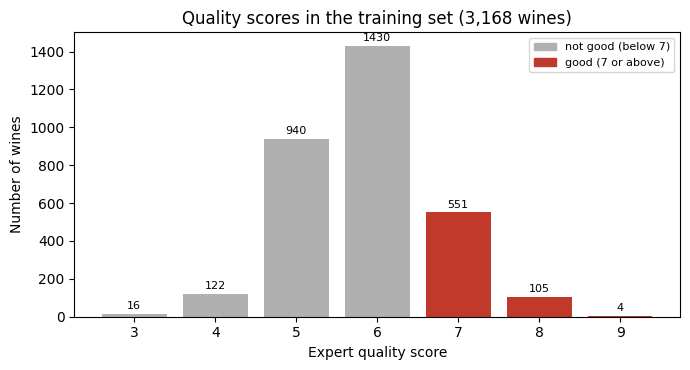

quality,3,4,5,6,7,8,9
wines,16,122,940,1430,551,105,4


In [19]:
import os
import matplotlib.pyplot as plt

os.makedirs('results', exist_ok=True)
counts = train_df['quality'].value_counts().reindex(range(3, 10), fill_value=0)

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(counts.index.astype(str), counts.values,
              color=['#b0b0b0' if q < 7 else '#c0392b' for q in counts.index])
ax.bar_label(bars, fontsize=8, padding=2)
ax.set(xlabel='Expert quality score', ylabel='Number of wines',
       title='Quality scores in the training set (3,168 wines)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#b0b0b0'), plt.Rectangle((0, 0), 1, 1, color='#c0392b')],
          labels=['not good (below 7)', 'good (7 or above)'], fontsize=8)
plt.tight_layout()
fig.savefig('results/quality_distribution.png', dpi=200)
plt.show()
counts.rename('wines').to_frame().T

In [20]:
cutoffs = pd.DataFrame({c: {'good wines': int((train_df['quality'] >= c).sum()),
                            'share good': (train_df['quality'] >= c).mean(),
                            'good wines per CV fold': (train_df['quality'] >= c).sum() / 10}
                        for c in (6, 7, 8)}).T
cutoffs.index.name = 'good if quality >='
cutoffs.to_csv('results/quality_cutoffs.csv')
cutoffs.round(3)

,good wines,share good,good wines per CV fold
good if quality >=,,,
6,2090.0,0.660,209.0
7,660.0,0.208,66.0
8,109.0,0.034,10.9


**Why 7.**
- **At 6 or above**, 2,090 of the 3,168 training wines (66%) would count as good, so *good* would describe the typical wine rather than a premium one, and a pre-screen for the tasting panel would have little to screen out.
- **At 8 or above**, only 109 wines (3.4%) are good, about 11 per CV fold. Estimates of PR-AUC, sensitivity and cost from 11 positives per fold would be very unstable, and a 793-wine test set with the same share would hold only about 27 good wines.
- **At 7 or above**, 660 wines (20.8%) are good, about 66 per fold: a rare but workable class that still means clearly above average.

The UCI description of the data says the quality classes *"are ordered and not balanced (e.g. there are many more normal wines than excellent or poor ones)"*, which matches the distribution above. We could not access the original paper (Cortez et al., 2009) to check whether it names a "very good" grade or a cut-off at 7, so we do not rely on it; the cut-off rests on the counts above.

# Part 2: Exploratory data analysis (training set only)

One row per unique wine (3,168 wines). This is the same data used for modelling: duplicate rows (repeat measurements of the same wine) were dropped before the split (Part 1). The test set is not loaded.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent plot style across all parts

sns.set_theme(style='whitegrid', palette='muted') 
# adds a light grid background to all plots, making it easier to read values off the axes
# uses softer, less saturated colours which look more professional than matplotlib's default bright colours

plt.rcParams['figure.dpi'] = 110 
# increases the resolution of plots so they appear sharper, especially on high-resolution screens

print('Environment ready.')

Environment ready.


In [22]:
wine_white = pd.read_csv("datasets/winequality-white-train.csv")

### Basic Checks

In [23]:
wine_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.18,0.40,1.6,0.047,22.0,102.0,0.99370,3.28,0.44,10.7,5
1,6.9,0.24,0.36,20.8,0.031,40.0,139.0,0.99750,3.20,0.33,11.0,6
2,6.3,0.18,0.36,1.2,0.034,26.0,111.0,0.99074,3.16,0.51,11.0,6
3,6.2,0.21,0.38,6.8,0.036,64.0,245.0,0.99510,3.06,0.36,9.3,6
4,8.5,0.26,0.21,16.2,0.074,41.0,197.0,0.99800,3.02,0.50,9.8,3


In [24]:
# Shape
wine_white.shape

(3168, 12)

In [25]:
# Data types
wine_white.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [26]:
# Summary statistics
wine_white.describe().round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00,3168.00
mean,6.84,0.28,0.33,5.85,0.05,34.75,136.99,0.99,3.19,0.49,10.59,5.86
std,0.87,0.10,0.12,4.71,0.02,16.62,42.81,0.00,0.15,0.11,1.22,0.89
min,3.80,0.08,0.00,0.60,0.01,2.00,9.00,0.99,2.72,0.22,8.00,3.00
25%,6.30,0.21,0.27,1.60,0.04,23.00,106.00,0.99,3.09,0.41,9.50,5.00
50%,6.80,0.26,0.32,4.70,0.04,33.00,133.00,0.99,3.18,0.48,10.40,6.00
75%,7.30,0.33,0.39,8.80,0.05,45.00,166.00,1.00,3.29,0.55,11.40,6.00
max,14.20,1.00,1.66,26.05,0.29,146.50,366.50,1.00,3.82,1.08,14.05,9.00


In [27]:
# Null values
wine_white.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

0 null values

### Binarising `quality`
We binarise quality with quality >= 7 being a good wine, and quality < 7 being a bad wine

In [28]:
wine_white['quality'] = (wine_white['quality'] >= 7).astype(int)

In [29]:
wine_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.18,0.40,1.6,0.047,22.0,102.0,0.99370,3.28,0.44,10.7,0
1,6.9,0.24,0.36,20.8,0.031,40.0,139.0,0.99750,3.20,0.33,11.0,0
2,6.3,0.18,0.36,1.2,0.034,26.0,111.0,0.99074,3.16,0.51,11.0,0
3,6.2,0.21,0.38,6.8,0.036,64.0,245.0,0.99510,3.06,0.36,9.3,0
4,8.5,0.26,0.21,16.2,0.074,41.0,197.0,0.99800,3.02,0.50,9.8,0


In [30]:
wine_white['quality'].value_counts()

quality
0    2508
1     660
Name: count, dtype: int64

In [31]:
print("Positive class rate:", wine_white['quality'].mean().round(3))

Positive class rate: 0.208


### Univariate Distributions

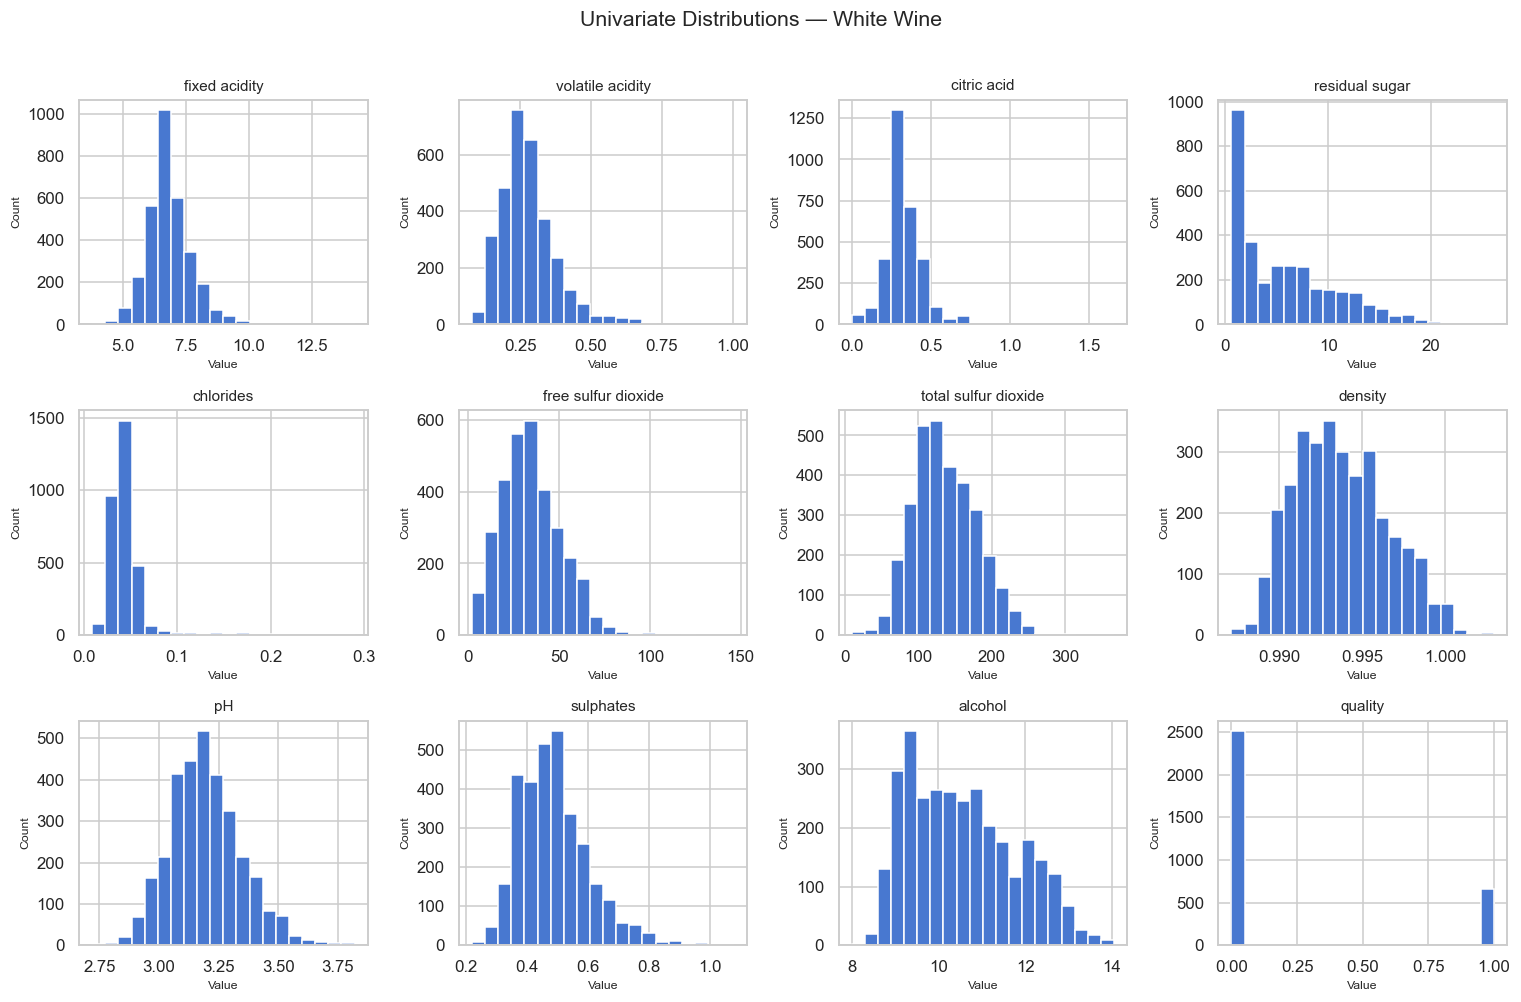

In [32]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))

# Flatten the 2D axes array (shape 3x4) into a 1D array of 12 elements
for ax, col in zip(axes.flatten(), wine_white.columns):
    ax.hist(wine_white[col], bins=20, edgecolor='white')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Value', fontsize=8)
    ax.set_ylabel('Count', fontsize=8)

plt.suptitle('Univariate Distributions — White Wine', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

##### Well behaved
`pH`: Unimodal and fully symmetric, forming a classic bell-shaped distribution.

`Density`: Nearly symmetric and bell-shaped, with a subtle shift toward higher values.

`Total Sulfur Dioxide`: Broad, well-behaved bell-shaped distribution.

`Fixed Acidity`: Mostly symmetric, trailing off slightly into higher values.

##### Skewed/Multimodal
`Volatile Acidity`: Right-skewed, concentrated heavily at low values with a long upper tail.

`Free Sulfur Dioxide`: Right-skewed, with most observations clustered in the lower region tapering toward higher values.

`Sulphates`: Moderately right-skewed, peaking early and trailing off gradually.

`Citric Acid`: Sharply peaked around a central concentration, with a thin upper tail.

`Residual Sugar`: Heavily right-skewed, with the vast majority concentrated at low levels and a long tail extending toward sweeter wines.

`Chlorides`: Tightly clustered near low values with a severe, sparse upper tail.

`Alcohol`: Bimodal with distinct secondary peaks

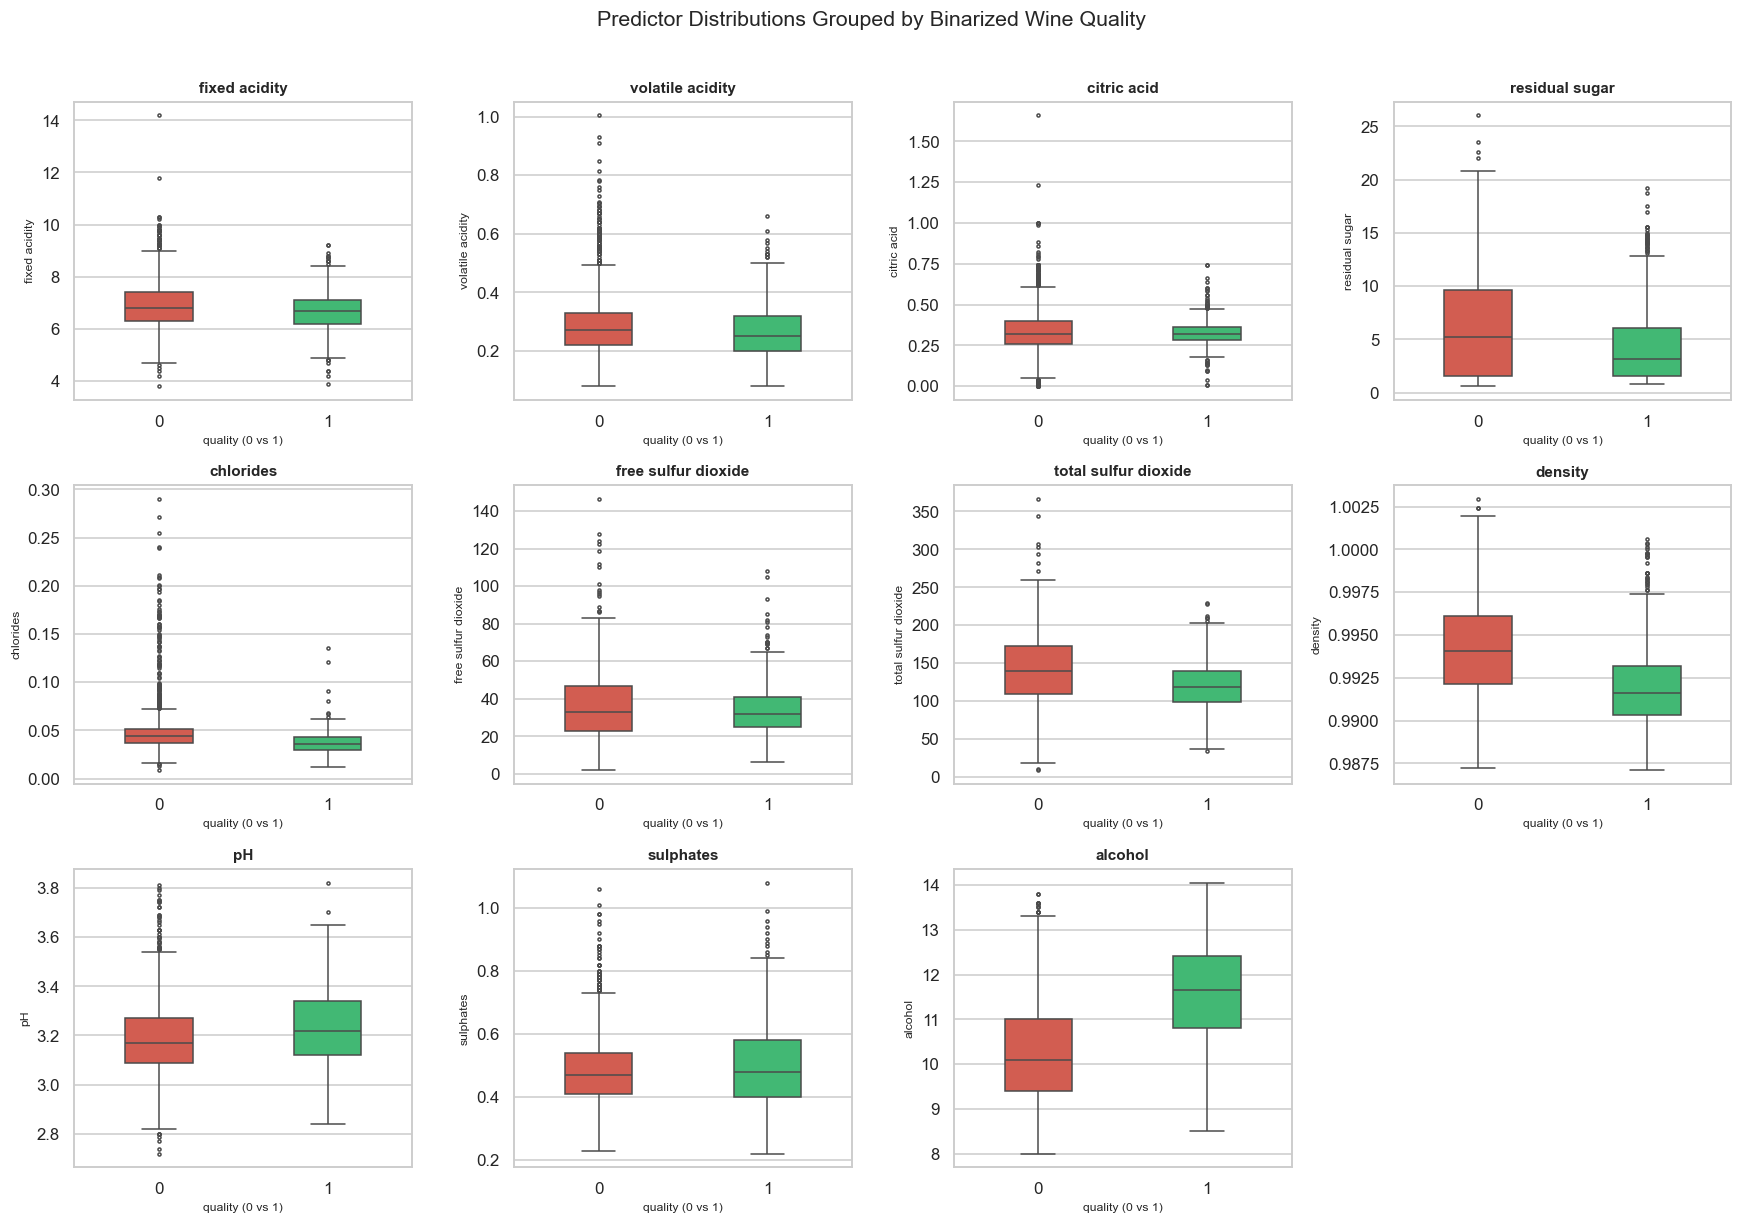

In [33]:
# Predictors excluding the binarized target 'quality'
predictors = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes_flat = axes.flatten()

for i, pred in enumerate(predictors):
    ax = axes_flat[i]
    sns.boxplot(
        data=wine_white, 
        x='quality', 
        y=pred, 
        hue='quality',    # Assign hue to match x
        legend=False,     # Suppress extra legend
        ax=ax, 
        palette=['#e74c3c', '#2ecc71'], 
        width=0.4,
        fliersize=2
    )
    ax.set_title(pred, fontsize=10, fontweight='bold')
    ax.set_xlabel('quality (0 vs 1)', fontsize=8)
    ax.set_ylabel(pred, fontsize=8)

# Remove the empty 12th panel in the 3x4 grid
fig.delaxes(axes_flat[-1])

plt.suptitle('Predictor Distributions Grouped by Binarized Wine Quality', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

In [34]:
# Class medians behind the box plots (training set)
medians = wine_white.groupby('quality')[predictors].median().T
medians.columns = ['median not good', 'median good']
medians.round(4)

,median not good,median good
fixed acidity,6.800,6.7000
volatile acidity,0.270,0.2500
citric acid,0.320,0.3200
residual sugar,5.200,3.1500
chlorides,0.044,0.0360
free sulfur dioxide,33.000,32.0000
total sulfur dioxide,139.000,118.0000
density,0.994,0.9916
pH,3.170,3.2200
sulphates,0.470,0.4800


Some variables that may be significant based on visual inspection of the box plots:

- `alcohol`: Positive class shows a significantly higher median and overall distribution compared to negative class, with minimal overlap in their interquartile ranges. 
- `density`: Positive class has a noticeably lower median density than negative class, displaying clear visual separation between the two distributions. 
- `residual sugar`: Negative class has a higher median and a noticeably wider distribution extending into higher concentrations compared to positive class.   
- `total sulfur dioxide`: Positive class exhibits a lower median concentration compared to negative class.
- `chlorides`: Positive class has a lower median (0.036 vs 0.044 g/dm³), although both classes are tightly clustered with a long upper tail.

The boxes and whiskers of the two classes overlap on every variable, so no single measurement separates them and a multivariable classifier is needed.

### Correlation Matrix

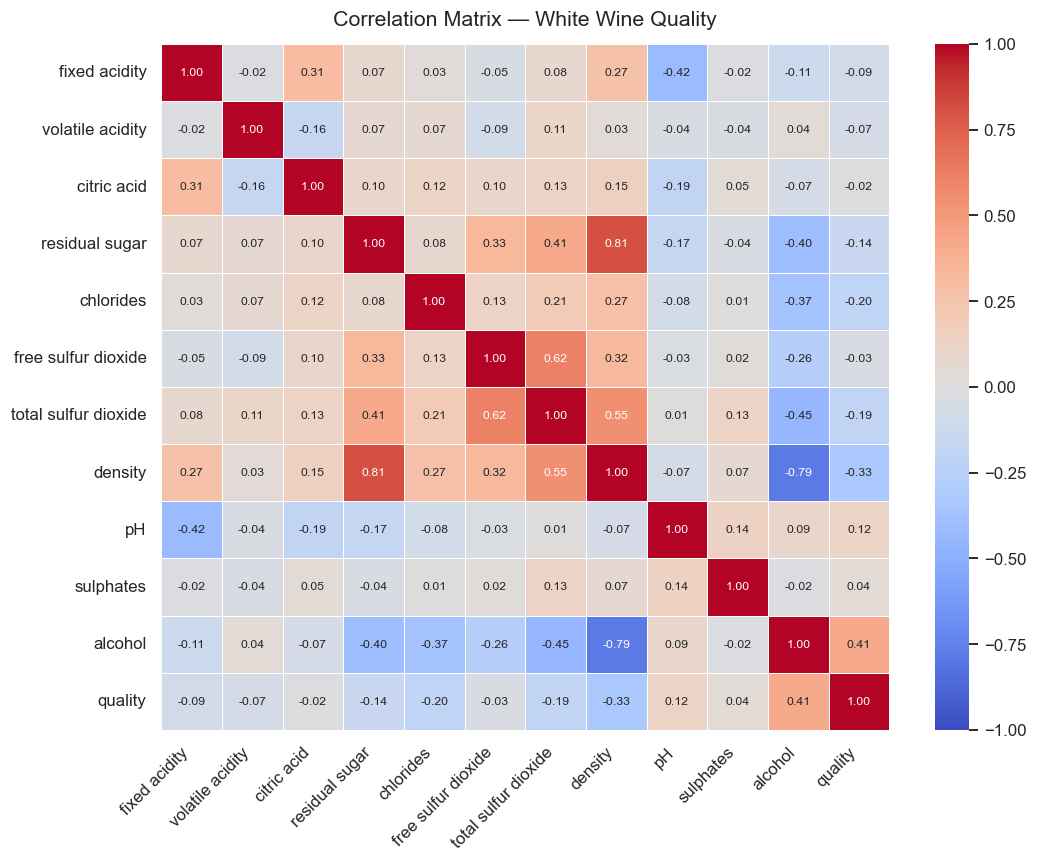

In [35]:
# Compute correlation matrix for the white wine dataset
corr = wine_white.corr()

# Increased figure size (10x8) so numbers and labels don't overlap with 12 features
fig, ax = plt.subplots(figsize=(10, 8))

# Draw the heatmap
sns.heatmap(
    corr, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm',
    vmin=-1, 
    vmax=1, 
    linewidths=0.5, 
    annot_kws={"size": 8},  # Slightly smaller text size for clarity
    ax=ax
)

# Formatting title and axis tick labels
ax.set_title('Correlation Matrix — White Wine Quality', fontsize=14, pad=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

- `density` $\leftrightarrow$ `residual sugar` ($r = 0.81$): This is the strongest positive correlation between any two predictors in the dataset. 
- `density` $\leftrightarrow$ `alcohol` ($r = -0.79$): This is the strongest negative correlation between any two predictors in the dataset. Higher alcohol content lowers the density of the wine.
- `alcohol` $\leftrightarrow$ `quality` ($r = 0.41$): Has the strongest direct positive correlation with quality.
- `density` $\leftrightarrow$ `quality` ($r = -0.33$): Has the strongest negative correlation with quality. However, note that density is heavily tied to alcohol ($r = -0.79$), which has the highest positive correlation with `quality`
- `citric acid` $\leftrightarrow$ `quality` ($r = -0.02$): The weakest correlation with quality of all 11 predictors. All 11 predictors are examined here; which ones each classifier uses is decided in Part 3. The selected logistic regression (and LDA) use 6 predictors without citric acid, while Gaussian NB keeps it among its 3.

### Candidate transformations
Naive Bayes and LDA assume Gaussian predictors within each class, so strong right skew hurts them. Rule: take the natural log of a predictor if its raw skewness is above 0.75 and the log reduces |skewness|. A log has no fitted parameters, so applying it outside the CV pipeline causes no leakage.

In [36]:
X_raw = wine_white[predictors]
skew = pd.DataFrame({
    'raw skew': X_raw.skew(),
    'log skew': np.log(X_raw.where(X_raw > 0)).skew(),
})
skew['take log'] = (skew['raw skew'] > 0.75) & (skew['log skew'].abs() < skew['raw skew'].abs())
skew.round(2)

,raw skew,log skew,take log
fixed acidity,0.71,0.09,False
volatile acidity,1.51,0.14,True
citric acid,1.36,-2.14,False
residual sugar,0.91,-0.06,True
chlorides,4.72,1.03,True
free sulfur dioxide,0.81,-0.91,False
total sulfur dioxide,0.39,-0.94,False
density,0.32,0.32,False
pH,0.45,0.29,False
sulphates,0.89,0.16,True


We log `volatile acidity`, `residual sugar`, `chlorides` and `sulphates`. `citric acid` has zeros and becomes more skewed under a log. `free sulfur dioxide` overshoots into left skew (0.81 to -0.91), so both stay on the raw scale. This list is stored once in `LOG_FEATURES` (Part 0) and used by every later part.

#### pH or hydrogen-ion concentration?
One alternative is to replace `pH` with the hydrogen-ion concentration $[H^+] = 10^{-\mathrm{pH}}$, which is linear in acidity. But pH is already a log scale ($\mathrm{pH} = -\log_{10}[H^+]$), so converting it undoes a log. We check it with the same skewness rule as above.

In [37]:
h_conc = 10 ** (-X_raw['pH'])
pd.DataFrame({'skew': [X_raw['pH'].skew(), h_conc.skew()]},
             index=['pH (log scale)', '[H+] = 10^-pH']).round(2)

,skew
pH (log scale),0.45
[H+] = 10^-pH,0.67


Converting to $[H^+]$ makes the predictor more skewed (0.67 vs 0.45), which works against the Gaussian assumptions of LDA and Naive Bayes, so we keep `pH`. (For tree-based models the choice would make no difference, because a monotone transform of a single predictor does not change which splits are possible.)

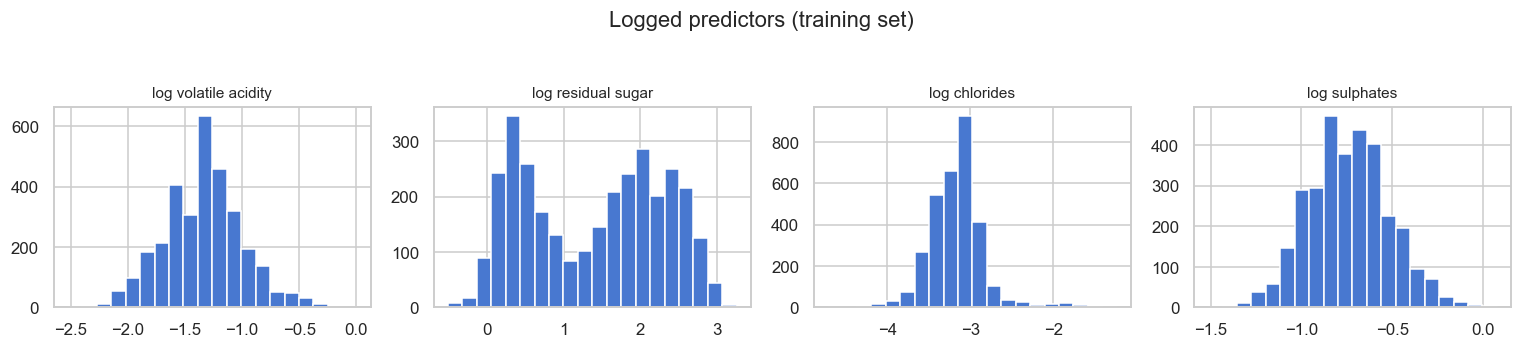

In [38]:
fig, axes = plt.subplots(1, len(LOG_FEATURES), figsize=(14, 3))
X_log = transform(X_raw)
for ax, col in zip(axes, LOG_FEATURES):
    ax.hist(X_log[f'log {col}'], bins=20, edgecolor='white')
    ax.set_title(f'log {col}', fontsize=10)
plt.suptitle('Logged predictors (training set)', y=1.05)
plt.tight_layout()
plt.show()

### Collinearity (VIF)
VIFs on the transformed predictors. Values above 10 indicate serious collinearity, which makes logistic coefficients unstable and breaks Naive Bayes' independence assumption.

In [39]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

Xc = sm.add_constant(X_log)
vif = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
    index=X_log.columns, name='VIF',
).sort_values(ascending=False)
vif.round(1)

density                 15.4
alcohol                  6.5
log residual sugar       5.9
total sulfur dioxide     2.3
fixed acidity            2.2
free sulfur dioxide      1.8
pH                       1.7
log chlorides            1.4
citric acid              1.2
log volatile acidity     1.2
log sulphates            1.1
Name: VIF, dtype: float64

`density` has by far the largest VIF: it is almost fully explained by residual sugar and alcohol, matching the correlations above. We do not drop `density` by hand; predictors are chosen separately for each classifier in Part 3. The selected logistic model keeps `density` and `residual sugar` and leaves out `alcohol`, the predictor they almost reconstruct. Collinearity inflates the variance of the logistic coefficients (so individual odds ratios in Part 5 should be read with care) but does not by itself harm prediction. It does violate Naive Bayes' independence assumption, which is discussed in the comparison.

### Class-conditional spread (LDA assumption)
LDA assumes both classes share one covariance matrix. Ratios of class standard deviations far from 1 are a warning sign.

In [40]:
y_bin = wine_white['quality']  # already binarised above
sd = X_log.groupby(y_bin).std().T
sd.columns = ['SD not good', 'SD good']
sd['ratio good / not good'] = sd['SD good'] / sd['SD not good']
sd.round(3)

,SD not good,SD good,ratio good / not good
fixed acidity,0.887,0.785,0.885
log volatile acidity,0.337,0.351,1.041
citric acid,0.131,0.082,0.627
log residual sugar,0.930,0.778,0.837
log chlorides,0.332,0.274,0.826
free sulfur dioxide,17.279,13.804,0.799
total sulfur dioxide,44.497,30.789,0.692
density,0.003,0.002,0.895
pH,0.148,0.156,1.052
log sulphates,0.214,0.258,1.205


Most ratios lie within about 0.8-1.2, but good wines are noticeably less spread on `citric acid` (0.63) and `total sulfur dioxide` (0.69). Neither predictor is in LDA's final 6-predictor subset (Part 3). The equal-covariance assumption is therefore only approximately met even within white wine alone, which is one more reason not to pool red and white wines (whose chemistry differs far more). We keep LDA as required by the brief and interpret its results with this in mind.

# Part 3: Model comparison with per-model predictor selection (training set only)

Choose each classifier's predictors, cross-validate every candidate on the same folds, select one winner. The test set is not loaded in this part.

### Decisions fixed before looking at any results

**Application.** A Vinho Verde producer pre-screens white wine batches before paying for an expert tasting panel. Positive = good wine (quality 7 or above; the cut-off is justified in Part 1).
- False positive: a mediocre batch is sent to the panel, wasting one tasting ($c_{FP} = 1$).
- False negative: a good batch is never tasted and is sold at the standard price, losing the premium margin ($c_{FN}$).

**Why $c_{FN} = 3$.** We value the price premium of a good batch at about 4 tasting fees. A missed good batch loses that premium but saves the fee that tasting it would have cost, so a false negative costs about $4 - 1 = 3$ fees, against 1 fee for a false positive. The premium is an assumption, not a measured figure, so Part 4 re-runs the analysis for $c_{FN}/c_{FP} \in \{1/3, 1/2, 1, 2, 3, 5, 10\}$.

**Data and folds.** One row per wine: repeat measurements of the same wine were removed before the split, leaving 3,168 training wines. All CV uses `StratifiedKFold(n_splits=10, shuffle=True, random_state=211)`; because every wine appears once, it sits in exactly one fold.

**CV metric: PR-AUC (average precision).** 20.8% of wines are good. PR-AUC measures how well a model ranks the rare good wines at the top and, unlike ROC-AUC or accuracy, is not flattered by the many easy negatives. ROC-AUC, sensitivity, specificity and confusion matrices are reported as supporting evidence, at the default threshold 0.5 and at the cost-optimal $t^* = c_{FP}/(c_{FP}+c_{FN}) = 0.25$.

**Candidates.** Logistic regression (unpenalised), LDA and Gaussian Naive Bayes, the three required by the brief. Candidate predictors: all 11, with the four log transforms (`transform` (Part 0)). Each pipeline selects its predictors, then standardises them with a `StandardScaler` refitted on every training fold.

#### The one-SE rule (`one_se_choice` (Part 0)), used for every choice made by CV
For each candidate, compute the mean CV PR-AUC and its $SE = SD_{folds}/\sqrt{\text{number of folds}}$. Find the candidate with the highest mean. The **cut-off** is that best mean minus the best candidate's SE. Among the candidates at or above the cut-off, choose the **simplest**:
- for predictor subsets: the fewest predictors, ties broken by the higher mean;
- for models: the lowest expected cost per wine at $t^* = 0.25$, ties broken by the higher mean PR-AUC.

#### Predictor selection, separately for each classifier
- **Final subset.** On the full training set, score all $2^{11} - 1 = 2{,}047$ subsets for each classifier on the 10 CV folds and choose one with `one_se_choice`.
- **Honest evaluation (nested CV).** Choosing among 2,047 subsets by their CV score inflates that score. So for each of the 10 outer folds, the same selection is run on the outer-training wines only (inner `StratifiedKFold(5, shuffle=True, random_state=211)`), the chosen subset is fitted on all outer-training wines, and the outer-validation fold is scored. These outer-fold scores and probabilities are the performance estimates used everywhere below and in Part 4.
- **Reference.** All 11 predictors for each classifier on the same outer folds, with the paired difference (nested per-model subset − all 11).

#### Model selection
`one_se_choice` applied to the nested PR-AUC of the three classifiers, with expected cost at $t^* = 0.25$ as the simplicity criterion.

In [41]:
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
from sklearn.model_selection import StratifiedKFold



sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
os.makedirs('results', exist_ok=True)

X, y = load_train()   # one row per wine, all 11 transformed predictors
splits = list(make_cv(10).split(X, y))
NAMES = list(candidate_models())
SUBSETS = all_subsets(ALL_COLUMNS)
T_STAR = C_FP / (C_FP + C_FN_BASE)
assert len(SUBSETS) == 2047
print(X.shape, '| share good =', y.mean().round(3), '| t* =', T_STAR)


def fold_metrics(y_true, prob):
    out = {'PR-AUC': average_precision_score(y_true, prob),
           'ROC-AUC': roc_auc_score(y_true, prob)}
    for t in (0.5, T_STAR):
        tn, fp, fn, tp = confusion_matrix(y_true, prob >= t, labels=[0, 1]).ravel()
        out[f'Sensitivity @{t:g}'] = tp / (tp + fn)
        out[f'Specificity @{t:g}'] = tn / (tn + fp)
    out[f'Cost/wine @{T_STAR:g}'] = expected_cost(y_true, prob, T_STAR, C_FN_BASE)
    return out


def mean_se(a, d=3):
    a = np.asarray(a)
    return f'{a.mean():.{d}f} ± {a.std(ddof=1) / np.sqrt(len(a)):.{d}f}'

(3168, 11) | share good = 0.208 | t* = 0.25


### Check the data and folds

In [42]:
train_df = load_split('train')
assert len(train_df) == 3168 and not train_df.duplicated().any()
fold_info = pd.DataFrame([{'fold': k, 'validation wines': len(va), 'good wines': int(y.iloc[va].sum())}
                          for k, (tr, va) in enumerate(splits)]).set_index('fold')
assert fold_info['good wines'].between(64, 68).all()
print('3,168 training wines, no duplicates; every fold has 66 ± 2 good wines.')
fold_info.T

3,168 training wines, no duplicates; every fold has 66 ± 2 good wines.


fold,0,1,2,3,4,5,6,7,8,9
validation wines,317,317,317,317,317,317,317,317,316,316
good wines,66,66,66,66,66,66,66,66,66,66


### Runtime estimate

Time 20 subsets × 1 fold for each classifier, then scale to the full run: 2,047 subsets × (10 folds on the full training set + 10 outer folds × 5 inner folds) per classifier, spread over the CPU cores used by joblib.

In [43]:
from joblib import cpu_count
tr0, va0 = splits[0]
per_fit = {}
for name in NAMES:
    t0 = time.perf_counter()
    for cols in SUBSETS[::100][:20]:
        candidate_models(cols)[name].fit(X.iloc[tr0], y.iloc[tr0]).predict_proba(X.iloc[va0])
    per_fit[name] = (time.perf_counter() - t0) / 20

INNER_K = 5
fits_per_model = len(SUBSETS) * (10 + 10 * INNER_K)
est_min = sum(per_fit.values()) * fits_per_model / cpu_count() / 60
print({k: f'{1000 * v:.1f} ms per fit' for k, v in per_fit.items()})
print(f'Estimated total: about {est_min:.0f} min on {cpu_count()} cores (assumes all cores are equally fast)')
if est_min > 90:
    INNER_K = 3
print('Inner folds:', INNER_K)

{'Logistic': '4.7 ms per fit', 'LDA': '3.6 ms per fit', 'Gaussian NB': '3.1 ms per fit'}
Estimated total: about 2 min on 10 cores (assumes all cores are equally fast)
Inner folds: 5


The estimate is under 90 minutes, so the inner CV keeps the pre-stated 5 folds.

In [44]:
assert INNER_K == 5, 'Estimate over 90 minutes: update the markdown above.'

### Final subset for each classifier (full training set, 10 folds)

Every subset is scored on the 10 CV folds; scores are cached in `results/subsets/` so an interrupted run resumes. `one_se_choice` then picks the subset.

In [45]:
CACHE = 'results/subsets'
os.makedirs(CACHE, exist_ok=True)
warn_total = {'convergence': 0, 'other': 0}


def cached_scores(name, X_, y_, fold_list, tag):
    """Scores of every subset on the given folds, from cache if available."""
    path = f'{CACHE}/{tag}_{name.replace(" ", "_")}.csv'
    if os.path.exists(path):
        scores = pd.read_csv(path)
    else:
        scores, warn = subset_scores(name, X_, y_, fold_list)
        scores['n_conv_warnings'], scores['n_other_warnings'] = warn['convergence'], warn['other']
        scores.to_csv(path, index=False)
    assert len(scores) == len(SUBSETS)
    warn_total['convergence'] += int(scores['n_conv_warnings'].iloc[0])
    warn_total['other'] += int(scores['n_other_warnings'].iloc[0])
    return scores


def choose_subset(scores):
    cand = scores.set_index('subset').rename(columns={'size': 'simplicity'})
    chosen, cutoff, best = one_se_choice(cand)
    return chosen.split('|'), cutoff, best.split('|')


t_full = time.perf_counter()
full_scores, final, full_cutoff, full_best = {}, {}, {}, {}
for name in NAMES:
    full_scores[name] = cached_scores(name, X, y, splits, 'fulltrain')
    final[name], full_cutoff[name], full_best[name] = choose_subset(full_scores[name])
full_minutes = (time.perf_counter() - t_full) / 60

pd.DataFrame({name: {
    'best subset size': len(full_best[name]),
    'best mean PR-AUC': round(full_scores[name]['mean'].max(), 4),
    'one-SE cut-off': round(full_cutoff[name], 4),
    'chosen size': len(final[name]),
    'chosen mean PR-AUC (optimistic)': round(full_scores[name].set_index('subset').loc['|'.join(final[name]), 'mean'], 4),
    'chosen predictors': ', '.join(final[name]),
} for name in NAMES})

,Logistic,LDA,Gaussian NB
best subset size,8,9,7
best mean PR-AUC,0.5563,0.5571,0.532
one-SE cut-off,0.5387,0.5415,0.5162
chosen size,6,6,3
chosen mean PR-AUC (optimistic),0.5451,0.5424,0.5181
chosen predictors,"fixed acidity, log residual sugar, free sulfur...","fixed acidity, log residual sugar, free sulfur...","citric acid, pH, alcohol"


#### Trade-off between accuracy and simplicity

For each number of predictors, the best CV PR-AUC achieved by any subset of that size (±1 SE), on the full training set. These scores come from the same data used to choose the subsets, so they are slightly optimistic; the honest estimates are the nested ones below.

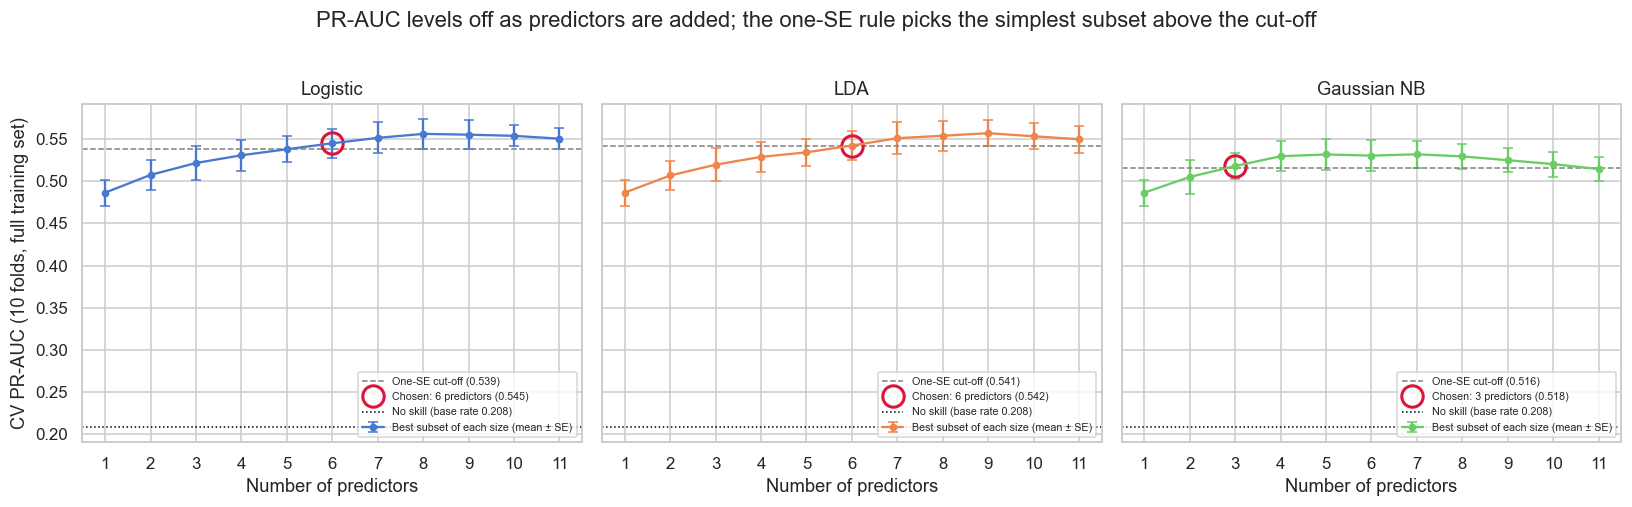

In [46]:
best_by_size = {name: full_scores[name].sort_values('mean').groupby('size').tail(1).set_index('size').sort_index()
                for name in NAMES}
colours = dict(zip(NAMES, sns.color_palette('muted', 3)))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, name in zip(axes, NAMES):
    b = best_by_size[name]
    ax.errorbar(b.index, b['mean'], yerr=b['se'], marker='o', ms=4, capsize=3, color=colours[name],
                label='Best subset of each size (mean ± SE)')
    ax.axhline(full_cutoff[name], color='grey', ls='--', lw=1, label=f'One-SE cut-off ({full_cutoff[name]:.3f})')
    k = len(final[name])
    chosen_mean = full_scores[name].set_index('subset').loc['|'.join(final[name]), 'mean']
    ax.plot(k, chosen_mean, 'o', ms=14, mfc='none', mec='crimson', mew=2,
            label=f'Chosen: {k} predictors ({chosen_mean:.3f})')
    ax.axhline(y.mean(), color='black', ls=':', lw=1, label=f'No skill (base rate {y.mean():.3f})')
    ax.set(title=name, xlabel='Number of predictors', xticks=range(1, 12))
    ax.legend(fontsize=7, loc='lower right')
axes[0].set_ylabel('CV PR-AUC (10 folds, full training set)')
fig.suptitle('PR-AUC levels off as predictors are added; the one-SE rule picks the simplest subset above the cut-off', y=1.02)
plt.tight_layout()
fig.savefig('results/subset_tradeoff.png', dpi=200, bbox_inches='tight')
plt.show()

**Reading.** For every classifier, PR-AUC climbs quickly over the first few predictors and then levels off: logistic regression gains 0.058 going from 1 to 6 predictors but only 0.011 more at its best (8 predictors, 0.556), and LDA and Gaussian NB behave the same way (Naive Bayes even declines after 7, because correlated predictors break its independence assumption). Near the top the differences are smaller than one SE (about 0.017), so the "best" size is not reliably better than its neighbours. The one-SE rule therefore chooses the simplest subset that is not meaningfully worse than the best: **6 predictors for logistic regression and LDA, 3 for Gaussian NB**. For logistic regression, 5 predictors (0.538) fall just below the cut-off (0.539).

### Honest evaluation: nested CV

For each outer fold, the selection above is repeated on the outer-training wines only (inner 5-fold CV), the chosen subset is fitted on all outer-training wines and scored on the outer-validation fold. The all-11 reference uses the same outer folds.

In [47]:
t_nested = time.perf_counter()
nested = {n: [] for n in NAMES}
all11 = {n: [] for n in NAMES}
chosen = {n: [] for n in NAMES}
oof = pd.DataFrame({'y': y.values, 'fold': -1})
for f, (tr, va) in enumerate(splits):
    oof.loc[va, 'fold'] = f
    X_tr, y_tr = X.iloc[tr], y.iloc[tr]
    inner = list(StratifiedKFold(n_splits=INNER_K, shuffle=True, random_state=SEED).split(X_tr, y_tr))
    for name in NAMES:
        cols, _, _ = choose_subset(cached_scores(name, X_tr, y_tr, inner, f'outer{f}'))
        chosen[name].append(cols)
        for store, use in [(nested, cols), (all11, ALL_COLUMNS)]:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                m = candidate_models(use)[name].fit(X_tr, y_tr)
            warn_total['convergence'] += sum('Convergence' in w.category.__name__ for w in caught)
            assert m.named_steps['model'].n_features_in_ == len(use)
            prob = m.predict_proba(X.iloc[va])[:, 1]
            store[name].append({'fold': f, **fold_metrics(y.iloc[va].values, prob)})
            if store is nested:
                oof.loc[va, name] = prob
    print(f'outer fold {f} done ({(time.perf_counter() - t_nested) / 60:.1f} min)')
nested_minutes = (time.perf_counter() - t_nested) / 60
nested = {n: pd.DataFrame(v) for n, v in nested.items()}
all11 = {n: pd.DataFrame(v) for n, v in all11.items()}
assert not oof.isna().any().any()
print(f'Runtime: estimated about {est_min:.0f} min; actual {full_minutes + nested_minutes:.1f} min '
      f'(full-training selection {full_minutes:.1f}, nested {nested_minutes:.1f}; cached runs are faster).')
print(f'Warnings while fitting: {warn_total["convergence"]} convergence, {warn_total["other"]} other.')

outer fold 0 done (0.0 min)
outer fold 1 done (0.0 min)
outer fold 2 done (0.0 min)
outer fold 3 done (0.0 min)


outer fold 4 done (0.0 min)
outer fold 5 done (0.0 min)
outer fold 6 done (0.0 min)
outer fold 7 done (0.0 min)


outer fold 8 done (0.0 min)
outer fold 9 done (0.0 min)
Runtime: estimated about 2 min; actual 0.0 min (full-training selection 0.0, nested 0.0; cached runs are faster).
Warnings while fitting: 0 convergence, 0 other.


#### Does per-model selection help? Nested subset vs all 11 predictors

In [48]:
selection_vs_all11 = pd.DataFrame({name: {
    'subset sizes chosen in outer folds': f'{min(map(len, chosen[name]))}-{max(map(len, chosen[name]))}',
    'final subset size': len(final[name]),
    'nested PR-AUC (per-model subset)': mean_se(nested[name]['PR-AUC']),
    'all-11 PR-AUC': mean_se(all11[name]['PR-AUC']),
    'paired difference (subset - all 11)': mean_se(nested[name]['PR-AUC'] - all11[name]['PR-AUC']),
    'nested ROC-AUC': mean_se(nested[name]['ROC-AUC']),
    'all-11 ROC-AUC': mean_se(all11[name]['ROC-AUC']),
} for name in NAMES})
selection_vs_all11

,Logistic,LDA,Gaussian NB
subset sizes chosen in outer folds,4-7,4-7,2-5
final subset size,6,6,3
nested PR-AUC (per-model subset),0.535 ± 0.018,0.526 ± 0.018,0.510 ± 0.020
all-11 PR-AUC,0.551 ± 0.013,0.550 ± 0.016,0.514 ± 0.015
paired difference (subset - all 11),-0.016 ± 0.009,-0.024 ± 0.008,-0.005 ± 0.012
nested ROC-AUC,0.802 ± 0.011,0.798 ± 0.011,0.792 ± 0.010
all-11 ROC-AUC,0.819 ± 0.009,0.815 ± 0.010,0.796 ± 0.009


#### Stability: how many of the 10 outer folds kept each predictor

In [49]:
stability = pd.DataFrame(index=ALL_COLUMNS)
for name in NAMES:
    kept = pd.Series([c for cols in chosen[name] for c in cols]).value_counts()
    stability[f'{name}: folds kept (of 10)'] = kept.reindex(ALL_COLUMNS).fillna(0).astype(int)
    stability[f'{name}: final'] = ['✓' if c in final[name] else '' for c in ALL_COLUMNS]
for name in NAMES:
    print(f'{name}: {len({tuple(c) for c in chosen[name]})} distinct subsets across the 10 outer folds')
stability

Logistic: 4 distinct subsets across the 10 outer folds
LDA: 6 distinct subsets across the 10 outer folds
Gaussian NB: 6 distinct subsets across the 10 outer folds


,Logistic: folds kept (of 10),Logistic: final,LDA: folds kept (of 10),LDA: final,Gaussian NB: folds kept (of 10),Gaussian NB: final
fixed acidity,10,✓,9,✓,0,
log volatile acidity,0,,0,,0,
citric acid,0,,0,,9,✓
log residual sugar,10,✓,9,✓,0,
log chlorides,1,,5,,6,
free sulfur dioxide,8,✓,8,✓,0,
total sulfur dioxide,0,,0,,0,
density,10,✓,9,✓,0,
pH,10,✓,10,✓,8,✓
log sulphates,5,✓,4,✓,1,


**Reading.** Per-model selection gives up some PR-AUC compared with simply using all 11 predictors, and the nested estimate measures how much: −0.016 ± 0.009 for logistic regression (about 1.8 SEs), −0.024 ± 0.008 for LDA (about 3 SEs) and −0.005 ± 0.012 for Gaussian NB (within noise). This is the price of simplicity we accept: the selected logistic model uses 6 predictors instead of 11 for a loss of about 0.016 in PR-AUC (about 3% of its value).

The subsets chosen inside the outer folds vary in size (4-7 for logistic and LDA, 2-5 for Naive Bayes), because the inner 5-fold SEs are wide and many subsets clear the cut-off. The core predictors are stable: fixed acidity, log residual sugar, density and pH are kept in 9-10 of 10 folds by logistic regression and LDA, and alcohol and citric acid in 9-10 folds by Naive Bayes.

**Alcohol is not in the logistic or LDA subsets.** Alcohol is the strongest single predictor in EDA, but a wine's density is largely determined by its sugar and alcohol content; with density and residual sugar in the model, alcohol adds little, so the smallest good subsets use them instead. The density coefficient in Part 5 should be read as carrying mostly the alcohol effect. Naive Bayes treats predictors as independent, so it prefers predictors that overlap less (alcohol directly).

### Compare the three classifiers (nested CV)

Every metric is from outer folds that neither the model nor its predictor subset saw. Mean ± SE over the 10 outer folds.

In [50]:
folds = pd.concat([nested[n].assign(model=n) for n in NAMES], ignore_index=True)
metrics = [c for c in folds.columns if c not in ('model', 'fold')]
gm = folds.groupby('model', sort=False)
mean, se = gm[metrics].mean(), gm[metrics].std() / np.sqrt(10)
table = mean.round(3).astype(str) + ' ± ' + se.round(3).astype(str)
table['Predictors (final subset)'] = [len(final[n]) for n in table.index]
table.T

model,Logistic,LDA,Gaussian NB
PR-AUC,0.535 ± 0.018,0.526 ± 0.018,0.51 ± 0.02
ROC-AUC,0.802 ± 0.011,0.798 ± 0.011,0.792 ± 0.01
Sensitivity @0.5,0.308 ± 0.016,0.315 ± 0.014,0.447 ± 0.023
Specificity @0.5,0.953 ± 0.005,0.945 ± 0.007,0.886 ± 0.007
Sensitivity @0.25,0.676 ± 0.021,0.671 ± 0.015,0.721 ± 0.018
Specificity @0.25,0.79 ± 0.01,0.787 ± 0.01,0.738 ± 0.01
Cost/wine @0.25,0.369 ± 0.016,0.374 ± 0.015,0.381 ± 0.013
Predictors (final subset),6,6,3


### ROC and PR curves (pooled nested out-of-fold probabilities)

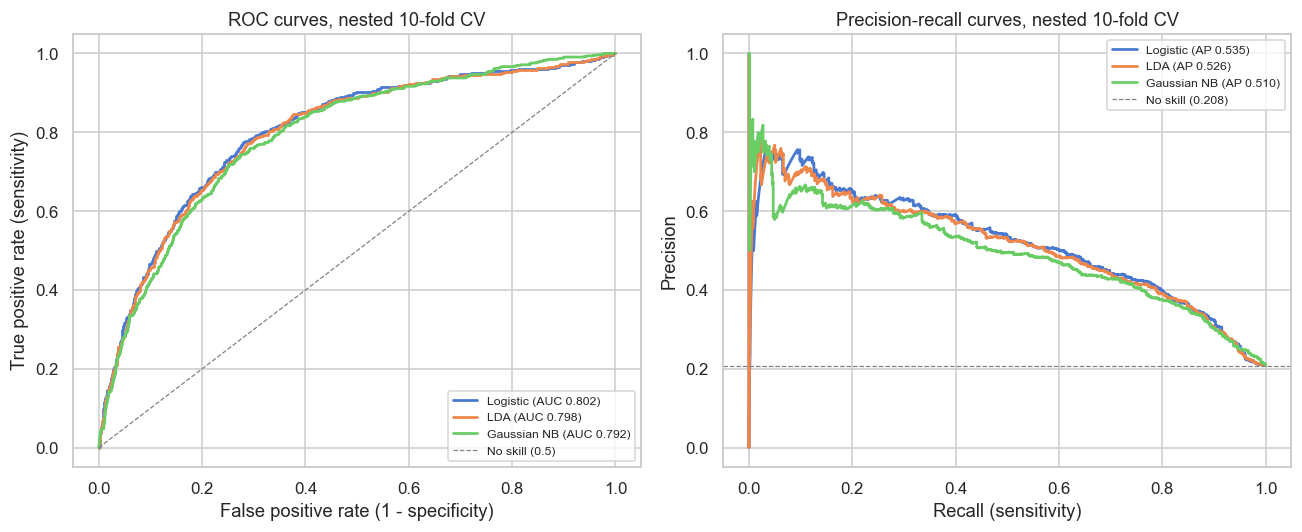

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name in NAMES:
    fpr, tpr, _ = roc_curve(oof['y'], oof[name])
    axes[0].plot(fpr, tpr, lw=1.8, color=colours[name], label=f"{name} (AUC {mean.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(oof['y'], oof[name])
    axes[1].plot(rec, prec, lw=1.8, color=colours[name], label=f"{name} (AP {mean.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color='grey', ls='--', lw=0.8, label='No skill (0.5)')
axes[0].set(xlabel='False positive rate (1 - specificity)', ylabel='True positive rate (sensitivity)',
            title='ROC curves, nested 10-fold CV')
axes[1].axhline(y.mean(), color='grey', ls='--', lw=0.8, label=f'No skill ({y.mean():.3f})')
axes[1].set(xlabel='Recall (sensitivity)', ylabel='Precision', title='Precision-recall curves, nested 10-fold CV')
axes[0].legend(fontsize=8, loc='lower right')
axes[1].legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

### Confusion matrices at $t^* = 0.25$ (pooled nested out-of-fold predictions)

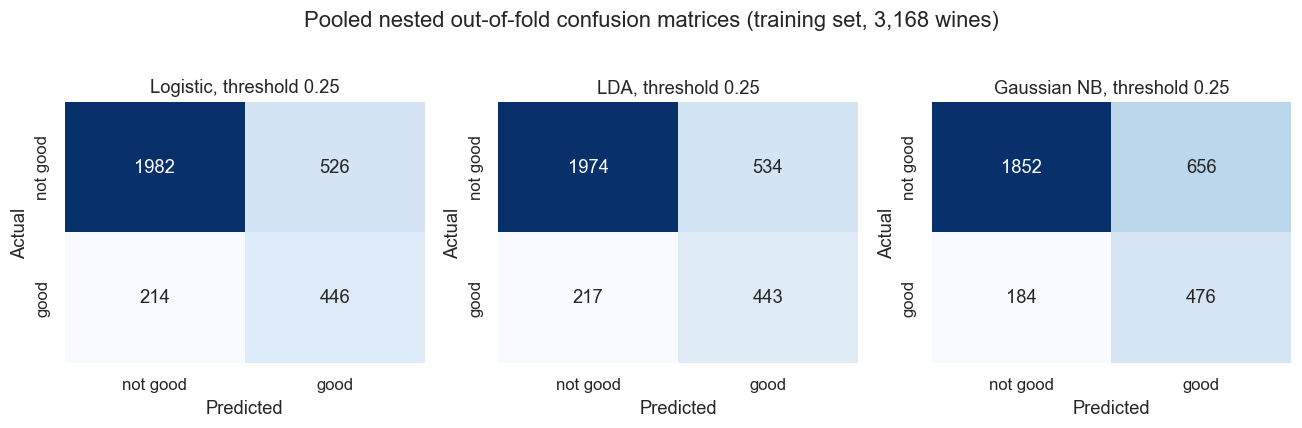

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
cms = {}
for ax, name in zip(axes, NAMES):
    cms[name] = confusion_matrix(oof['y'], oof[name] >= T_STAR)
    sns.heatmap(cms[name], annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['not good', 'good'], yticklabels=['not good', 'good'])
    ax.set(title=f'{name}, threshold {T_STAR:g}', xlabel='Predicted', ylabel='Actual')
fig.suptitle('Pooled nested out-of-fold confusion matrices (training set, 3,168 wines)', y=1.02)
plt.tight_layout()
plt.show()

### Apply the one-SE rule to choose the model

In [53]:
model_cand = pd.DataFrame({'mean': mean['PR-AUC'], 'se': se['PR-AUC'],
                           'simplicity': mean[f'Cost/wine @{T_STAR:g}']})
winner, model_cutoff, top = one_se_choice(model_cand)
model_cand['within one SE of best'] = model_cand['mean'] >= model_cutoff
print(f'Best mean PR-AUC: {top} ({model_cand.loc[top, "mean"]:.3f}); one-SE cut-off {model_cutoff:.3f}')
print('Eligible:', list(model_cand.index[model_cand['within one SE of best']]))
print('Selected model (lowest cost at t* among eligible):', winner, '| predictors:', final[winner])
model_cand.rename(columns={'mean': 'PR-AUC mean', 'se': 'PR-AUC SE', 'simplicity': 'cost at t* (mean)'}).round(4)

Best mean PR-AUC: Logistic (0.535); one-SE cut-off 0.516
Eligible: ['Logistic', 'LDA']
Selected model (lowest cost at t* among eligible): Logistic | predictors: ['fixed acidity', 'log residual sugar', 'free sulfur dioxide', 'density', 'pH', 'log sulphates']


,PR-AUC mean,PR-AUC SE,cost at t* (mean),within one SE of best
model,,,,
Logistic,0.5345,0.0184,0.3687,True
LDA,0.5257,0.0185,0.3741,True
Gaussian NB,0.5098,0.0200,0.3813,False


**Result.** Logistic regression (6 predictors) has the highest nested PR-AUC (0.535 ± 0.018), so the one-SE cut-off is 0.516. LDA (0.526) is within it; Gaussian NB (0.510) is just below. Of the two eligible models, logistic regression has the lower expected cost at $t^*$ (0.369 vs 0.374 per wine) and is selected. Logistic regression and LDA chose the same 6 predictors and are practically tied (cost gap 0.005, SE about 0.016); the pre-stated rule decides between them.

### Save the frozen specification and the CV results

Parts 4 and 5 read the model and its predictor subset from `results/selected_model.json`.

In [54]:
spec = {'name': winner,
        'predictors': final[winner],
        'n_predictors': len(final[winner]),
        'cv_pr_auc_mean': float(mean.loc[winner, 'PR-AUC']),
        'cv_pr_auc_se': float(se.loc[winner, 'PR-AUC']),
        'cv_roc_auc_mean': float(mean.loc[winner, 'ROC-AUC']),
        'cv_roc_auc_se': float(se.loc[winner, 'ROC-AUC']),
        'one_se_cutoff_models': float(model_cutoff),
        'cv': f'Nested: outer StratifiedKFold(10, shuffle, 211); inner StratifiedKFold({INNER_K}, shuffle, 211)',
        'all_models': {n: {'predictors': final[n], 'n_predictors': len(final[n]),
                           'one_se_cutoff_subsets': float(full_cutoff[n])} for n in NAMES}}
with open('results/selected_model.json', 'w') as f:
    json.dump(spec, f, indent=2)
folds.to_csv('results/cv_fold_scores.csv', index=False)
oof.to_csv('results/oof_probabilities.csv')
pd.concat([all11[n].assign(model=n) for n in NAMES]).to_csv('results/cv_fold_scores_all11.csv', index=False)
table.to_csv('results/model_comparison.csv')
selection_vs_all11.to_csv('results/selection_vs_all11.csv')
stability.to_csv('results/subset_stability.csv')
pd.DataFrame({n: cms[n].ravel() for n in NAMES}, index=['TN', 'FP', 'FN', 'TP']).to_csv('results/confusion_matrices_tstar.csv')
pd.concat({n: best_by_size[n][['mean', 'se', 'subset']] for n in NAMES}).to_csv('results/best_by_size.csv')
assert not test_load_attempts
print('Saved. Test set not loaded in this part.')
spec

Saved. Test set not loaded in this part.


{'name': 'Logistic',
 'predictors': ['fixed acidity',
  'log residual sugar',
  'free sulfur dioxide',
  'density',
  'pH',
  'log sulphates'],
 'n_predictors': 6,
 'cv_pr_auc_mean': 0.5345227561765242,
 'cv_pr_auc_se': 0.01844374776061791,
 'cv_roc_auc_mean': 0.8018381987202705,
 'cv_roc_auc_se': 0.010543537415940323,
 'one_se_cutoff_models': 0.5160790084159064,
 'cv': 'Nested: outer StratifiedKFold(10, shuffle, 211); inner StratifiedKFold(5, shuffle, 211)',
 'all_models': {'Logistic': {'predictors': ['fixed acidity',
    'log residual sugar',
    'free sulfur dioxide',
    'density',
    'pH',
    'log sulphates'],
   'n_predictors': 6,
   'one_se_cutoff_subsets': 0.538661039866455},
  'LDA': {'predictors': ['fixed acidity',
    'log residual sugar',
    'free sulfur dioxide',
    'density',
    'pH',
    'log sulphates'],
   'n_predictors': 6,
   'one_se_cutoff_subsets': 0.5414789185161306},
  'Gaussian NB': {'predictors': ['citric acid', 'pH', 'alcohol'],
   'n_predictors': 3,
   '

### Check on a design decision: log-transformed vs raw predictors

Each classifier's final subset, scored on the 10 CV folds with the logged predictors (as used) and with the same predictors on their original scale. Both are slightly optimistic because the subsets were chosen on these wines, but equally so; the paired difference is the quantity of interest.

In [55]:
raw = train_df[ALL_FEATURES].rename(columns={c: f'raw {c}' for c in ALL_FEATURES})
to_raw = {log_name(c): f'raw {c}' for c in ALL_FEATURES}
X_both = pd.concat([X, raw], axis=1)
check = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=RuntimeWarning)
    for name in NAMES:
        pr = {}
        for label, cols in [('log (used)', final[name]), ('raw', [to_raw[c] for c in final[name]])]:
            model = candidate_models(cols)[name]
            pr[label] = np.array([average_precision_score(
                y.iloc[va], clone(model).fit(X_both.iloc[tr], y.iloc[tr]).predict_proba(X_both.iloc[va])[:, 1])
                for tr, va in splits])
        check[name] = {'logged predictors in subset': sum(c.startswith('log ') for c in final[name]),
                       'log (used)': mean_se(pr['log (used)']), 'raw': mean_se(pr['raw']),
                       'paired difference (log - raw)': mean_se(pr['log (used)'] - pr['raw'])}
pd.DataFrame(check).T

,logged predictors in subset,log (used),raw,paired difference (log - raw)
Logistic,2,0.545 ± 0.017,0.540 ± 0.015,0.005 ± 0.006
LDA,2,0.542 ± 0.018,0.541 ± 0.015,0.002 ± 0.006
Gaussian NB,0,0.518 ± 0.015,0.518 ± 0.015,0.000 ± 0.000


**Reading.** On the final subsets the logs make little difference: +0.005 ± 0.006 for logistic regression and +0.002 ± 0.006 for LDA (2 of their 6 predictors are logged), and none for Gaussian NB, whose 3 predictors are not log-transformed. The logs were chosen in EDA for distribution shape (closer to the normality LDA and Naive Bayes assume), not to raise PR-AUC, and keeping them does no harm.

#### Summary: why each decision was made

| Decision | Main reason | Evidence | Where |
|---|---|---|---|
| White wine only | Red has too few good wines (184 unique) for stable 10-fold estimates; pooling breaks LDA's shared covariance | Class counts by colour | Part 1 |
| Good = quality 7 or above | 6+ makes two-thirds of wines "good"; 8+ leaves about 11 good wines per fold | Cut-off table (training set) | Part 1 |
| One row per wine, `StratifiedKFold(10)` | Repeat rows are the same wine measured twice; with one row per wine no copy can leak between folds | 937 repeat rows, identical on all 12 columns | Part 1 |
| Log-transform 4 predictors | Skew > 0.75 on the training set; closer to the normality LDA/NB assume | Skew table (EDA); log check above | Part 2, log check |
| Keep pH (not $[H^+]$) | $[H^+] = 10^{-pH}$ is more skewed (0.67 vs 0.45) | Skew table | Part 2 |
| Own predictor subset per classifier, by the one-SE rule | Simplest subset not meaningfully worse than the best | Trade-off graph; nested cost of simplicity: −0.016 PR-AUC for logistic vs all 11 | Predictor selection |
| PR-AUC to select | Good wines are the rare class (20.8%); ROC-AUC and accuracy are flattered by easy negatives | Stated before the results | Decisions cell |
| Model by the one-SE rule, then lowest cost at $t^*$ | Do not pick a model on noise; use the FP/FN costs | Logistic and LDA within one SE; logistic cheaper at $t^*$ | Model selection |
| $c_{FN} = 3$ | A good batch's premium is worth about 4 tasting fees; a miss loses it but saves one fee | Break-even range of the frozen threshold | Decisions cell, Part 4 |
| Operating threshold | Minimises CV expected cost at $c_{FN} = 3$ | Bootstrap interval around the theoretical 0.25 | Part 4 |

# Part 4: Extension: cost-based threshold analysis (training set only)

The single extension: how sensitivity, specificity and expected cost change with the classification threshold for the model selected in Part 3, how much screening with the model saves over policies that use no model, and how sensitive these conclusions are to the assumed cost ratio. Everything uses the nested out-of-fold CV probabilities from Part 3 (one row per wine; the predictor subset was chosen without the scored fold). The test set is not loaded.

### Decisions fixed before looking at any results

- **Costs** (from Part 3): $c_{FP} = 1$ (one wasted tasting), $c_{FN} = r$ (lost premium margin), base case $r = 3$: a good batch's premium is worth about 4 tasting fees, and a miss loses the premium but saves one fee, so it costs about 3 fees. Expected cost per wine $= (FP + r \cdot FN)/n$.
- **Cost ratios for the sensitivity check:** $r \in \{1/3, 1/2, 1, 2, 3, 5, 10\}$. Ratios below 1 cover a different framing, where the model is a standalone judge and a false positive costs more than a miss (see *Framing* below).
- **Operating point rule:** the threshold on a 0.01 grid that minimises the pooled out-of-fold expected cost at $r = 3$. The theoretical $t^* = 1/(1+r)$ is reported alongside it.
- **No-model policies**, with $\pi$ the share of good wines: *taste none* costs $r\pi$ per wine and *taste all* costs $c_{FP}(1-\pi) = 1-\pi$. The model's **saving** is measured against the cheaper of the two, in absolute terms (cost units per wine) and as a % of that cost.
- **Break-even range:** with the threshold frozen at the operating point, the model beats *taste all* when $FP + r\,FN < FP + TN$, i.e. $r < TN/FN$, and beats *taste none* when $FP + r\,FN < r(TP + FN)$, i.e. $r > FP/TP$. So it beats both for $FP/TP < r < TN/FN$.
- **Uncertainty of the operating point:** a bootstrap over wines (resampling rows, one row per wine), 2,000 replicates, re-finding the optimal threshold at $r = 3$ each time.

In [56]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve

import os


sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

def ratio_label(r):
    return f'1/{1 / r:g}' if r < 1 else f'{r:g}'

spec = json.load(open('results/selected_model.json'))
oof = pd.read_csv('results/oof_probabilities.csv', index_col=0)
y, prob, fold = oof['y'].values, oof[spec['name']].values, oof['fold'].values   # nested out-of-fold
assert len(y) == 3168
pi = y.mean()
n = len(y)
grid = np.round(np.arange(0.01, 1.00, 0.01), 2)

# FP and FN counts at every grid threshold, so cost(t, r) = (FP + r FN) / n
flag = prob[:, None] >= grid[None, :]
FP_t = (flag & (y[:, None] == 0)).sum(0)
FN_t = (~flag & (y[:, None] == 1)).sum(0)
print('Selected model:', spec['name'], f"({spec['n_predictors']} predictors)", '| wines =', n, '| share good =', round(pi, 3))

Selected model: Logistic (6 predictors) | wines = 3168 | share good = 0.208


### Sensitivity and specificity against the threshold

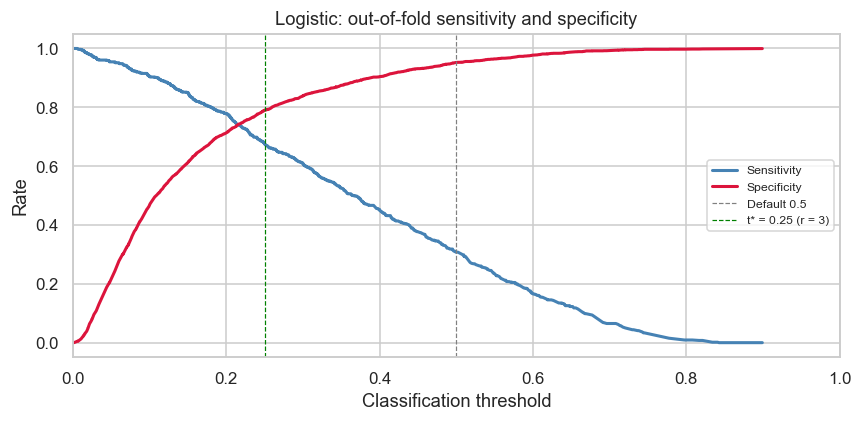

In [57]:
fpr, tpr, thr = roc_curve(y, prob)
fpr, tpr, thr = fpr[1:], tpr[1:], thr[1:]   # drop the artificial infinite threshold

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thr, tpr, lw=2, color='steelblue', label='Sensitivity')
ax.plot(thr, 1 - fpr, lw=2, color='crimson', label='Specificity')
ax.axvline(0.5, color='grey', ls='--', lw=0.8, label='Default 0.5')
ax.axvline(1 / (1 + C_FN_BASE), color='green', ls='--', lw=0.8,
           label=f't* = {1 / (1 + C_FN_BASE):.2f} (r = {C_FN_BASE})')
ax.set(xlim=(0, 1), xlabel='Classification threshold', ylabel='Rate',
       title=f'{spec["name"]}: out-of-fold sensitivity and specificity')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Expected cost against the threshold, for each cost ratio

Costs are divided by the cheaper of the two no-model policies, so a value below 1 means that screening with the model is cheaper than the best policy available without one.

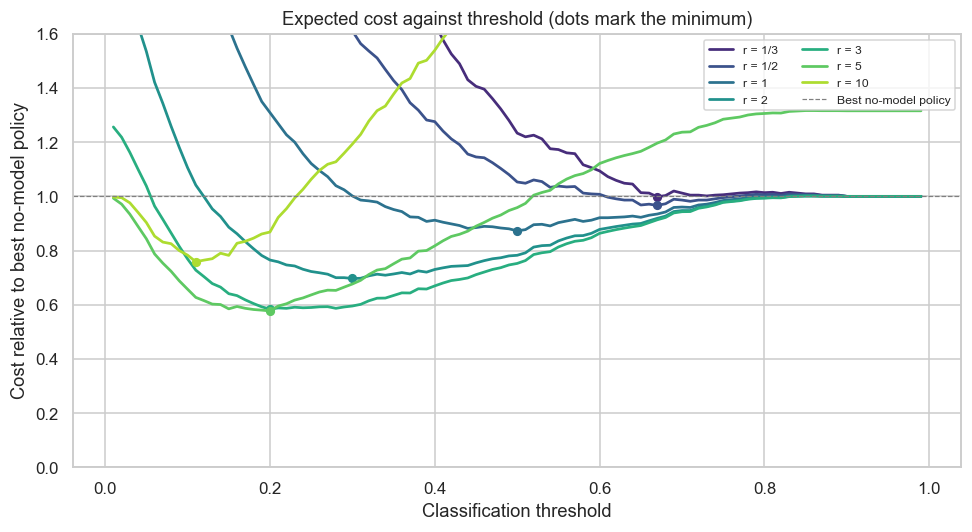

In [58]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = sns.color_palette('viridis', len(COST_RATIOS))
for r, col in zip(COST_RATIOS, colors):
    trivial = min(no_model_costs(pi, r).values())
    cost = (FP_t + r * FN_t) / n / trivial
    ax.plot(grid, cost, color=col, lw=1.8, label=f'r = {ratio_label(r)}')
    ax.plot(grid[cost.argmin()], cost.min(), 'o', color=col, ms=5)
ax.axhline(1, color='grey', ls='--', lw=0.8, label='Best no-model policy')
ax.set(xlabel='Classification threshold', ylabel='Cost relative to best no-model policy',
       title='Expected cost against threshold (dots mark the minimum)', ylim=(0, 1.6))
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### Sensitivity check across cost ratios

For each ratio: the theoretical $t^*$, the empirically optimal threshold on the pooled out-of-fold probabilities, the spread of the optimal threshold when it is found separately in each of the 10 folds, the range of thresholds whose cost stays within 5% of the minimum (how flat the cost curve is), and the saving over the better no-model policy.

In [59]:
def best_threshold(y_, p_, r):
    costs = np.array([expected_cost(y_, p_, t, r) for t in grid])
    return grid[costs.argmin()], costs

rows = []
for r in COST_RATIOS:
    costs = (FP_t + r * FN_t) / n
    t_opt = grid[costs.argmin()]
    per_fold = [best_threshold(y[fold == k], prob[fold == k], r)[0] for k in np.unique(fold)]
    flat = grid[costs <= 1.05 * costs.min()]
    nm = no_model_costs(pi, r)
    best_nm = min(nm, key=nm.get)
    rows.append({
        'r = c_FN/c_FP': r,
        't* theory': 1 / (1 + r),
        't optimal (pooled)': t_opt,
        'fold optimum mean': np.mean(per_fold),
        'fold optimum SD': np.std(per_fold, ddof=1),
        'within 5% of min': f'{flat.min():.2f}-{flat.max():.2f}',
        'cost @ t optimal': costs.min(),
        'cost @ t*': expected_cost(y, prob, 1 / (1 + r), r),
        'cost @ 0.5': expected_cost(y, prob, 0.5, r),
        'taste none': nm['taste none'],
        'taste all': nm['taste all'],
        'better no-model': best_nm,
        'saving (abs)': nm[best_nm] - costs.min(),
        'saving (%)': 100 * (1 - costs.min() / nm[best_nm]),
    })
sens = pd.DataFrame(rows)
sens.to_csv('results/cost_ratio_sensitivity.csv', index=False)
sens.round(3)

,r = c_FN/c_FP,t* theory,t optimal (pooled),fold optimum mean,fold optimum SD,within 5% of min,cost @ t optimal,cost @ t*,cost @ 0.5,taste none,taste all,better no-model,saving (abs),saving (%)
0,0.333,0.750,0.67,0.683,0.098,0.64-0.99,0.069,0.070,0.086,0.069,0.792,taste none,0.000,0.152
1,0.500,0.667,0.67,0.643,0.103,0.58-0.99,0.101,0.101,0.110,0.104,0.792,taste none,0.003,3.333
2,1.000,0.500,0.50,0.478,0.089,0.39-0.59,0.182,0.182,0.182,0.208,0.792,taste none,0.027,12.727
3,2.000,0.333,0.30,0.311,0.074,0.24-0.40,0.290,0.296,0.326,0.417,0.792,taste none,0.126,30.303
4,3.000,0.250,0.20,0.237,0.048,0.18-0.31,0.365,0.369,0.470,0.625,0.792,taste none,0.260,41.616
5,5.000,0.167,0.20,0.187,0.049,0.13-0.22,0.457,0.465,0.759,1.042,0.792,taste all,0.335,42.265
6,10.000,0.091,0.11,0.115,0.030,0.10-0.15,0.601,0.631,1.480,2.083,0.792,taste all,0.191,24.123


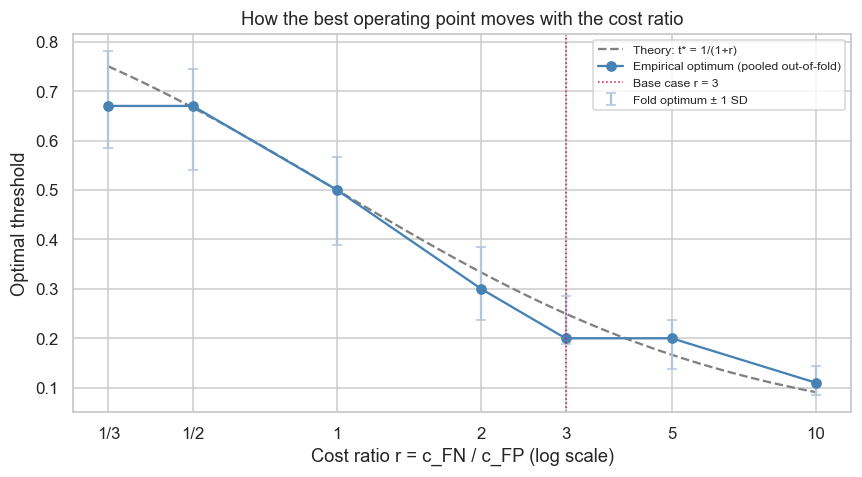

In [60]:
fig, ax = plt.subplots(figsize=(8, 4.5))
r_fine = np.logspace(np.log10(1/3), 1, 100)
ax.plot(r_fine, 1 / (1 + r_fine), color='grey', ls='--', label='Theory: t* = 1/(1+r)')
ax.errorbar(sens['r = c_FN/c_FP'], sens['fold optimum mean'], yerr=sens['fold optimum SD'],
            fmt='none', ecolor='lightsteelblue', capsize=3, label='Fold optimum ± 1 SD')
ax.plot(sens['r = c_FN/c_FP'], sens['t optimal (pooled)'], 'o-', color='steelblue',
        label='Empirical optimum (pooled out-of-fold)')
ax.axvline(C_FN_BASE, color='crimson', ls=':', lw=1, label=f'Base case r = {C_FN_BASE}')
ax.set_xscale('log')
ax.set_xticks(COST_RATIOS, [ratio_label(r) for r in COST_RATIOS])
ax.set(xlabel='Cost ratio r = c_FN / c_FP (log scale)', ylabel='Optimal threshold',
       title='How the best operating point moves with the cost ratio')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Calibration.** The empirical optimum differs from the theoretical $t^*$ by up to about 0.08 (0.67 vs 0.75 at $r = 1/3$, 0.20 vs 0.25 at $r = 3$, 0.11 vs 0.09 at $r = 10$), so the predicted probabilities are not perfectly calibrated; we note this but do not analyse calibration further. At the base case it matters little: the cost at $t^* = 0.25$ is 0.369 per wine against the minimum of 0.365.

### Operating point (base case $r = 3$)

In [61]:
base = sens.loc[sens['r = c_FN/c_FP'] == C_FN_BASE].iloc[0]
t_op = float(base['t optimal (pooled)'])
pred = prob >= t_op
tp, fp = int(np.sum(pred & (y == 1))), int(np.sum(pred & (y == 0)))
fn, tn = int(np.sum(~pred & (y == 1))), int(np.sum(~pred & (y == 0)))
precision = tp / (tp + fp)

per_1000 = pd.Series({
    'Sent to the panel': 1000 * (tp + fp) / n,
    '  of which good (caught)': 1000 * tp / n,
    '  of which not good (wasted tastings)': 1000 * fp / n,
    'Good wines not sent (missed)': 1000 * fn / n,
    'Good wines in total': 1000 * pi,
    'Precision of panel referrals (%)': 100 * precision,
    'Base rate of good wines (%)': 100 * pi,
}, name=f'Per 1,000 wines at threshold {t_op:g} (r = {C_FN_BASE})')
print(f'Sensitivity {tp / (tp + fn):.3f}, specificity {tn / (tn + fp):.3f}, '
      f'cost per wine {base["cost @ t optimal"]:.3f}')
per_1000.round(1).to_csv('results/per_1000.csv')
per_1000.round(1).to_frame()

Sensitivity 0.779, specificity 0.714, cost per wine 0.365


,"Per 1,000 wines at threshold 0.2 (r = 3)"
Sent to the panel,388.9
of which good (caught),162.2
of which not good (wasted tastings),226.6
Good wines not sent (missed),46.1
Good wines in total,208.3
Precision of panel referrals (%),41.7
Base rate of good wines (%),20.8


**Takeaway.** Per 1,000 wines, screening at threshold 0.20 sends about 389 to the panel and catches 162 of the 208 good wines (78%), missing 46; 42% of the wines sent to the panel are good, about twice the 20.8% base rate.

### Error analysis at the operating point

Which wines does the screen get wrong? At the chosen threshold, by true quality score (0-10 scale; *good* means 7 or above):
1. **False positives:** how many, and the share of all false positives at each quality score (`% of all FPs`);
2. **False negatives:** how many, and the share of all false negatives at each quality score (`% of all FNs`);
3. **Wines sent to the panel:** the share of wines at each quality score that are sent (`share sent (%)`, also plotted).

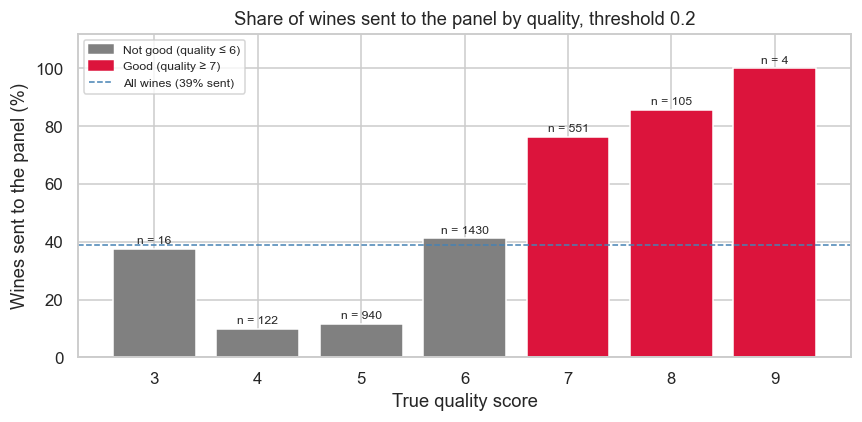

,wines,sent,share sent (%),false positives,false negatives,% of all FPs,% of all FNs
quality,,,,,,,
3,16,6,37.5,6,0,0.8,0.0
4,122,12,9.8,12,0,1.7,0.0
5,940,110,11.7,110,0,15.3,0.0
6,1430,590,41.3,590,0,82.2,0.0
7,551,420,76.2,0,131,0.0,89.7
8,105,90,85.7,0,15,0.0,10.3
9,4,4,100.0,0,0,0.0,0.0


In [62]:
from matplotlib.patches import Patch

quality = load_split('train')['quality'].to_numpy()   # same row order as the out-of-fold file
assert len(quality) == n
assert np.array_equal(quality >= 7, y == 1)

err = pd.DataFrame({'quality': quality, 'sent': pred, 'good': y == 1})
by_q = err.groupby('quality').agg(wines=('sent', 'size'), sent=('sent', 'sum'))
by_q['share sent (%)'] = 100 * by_q['sent'] / by_q['wines']
by_q['false positives'] = err[err['sent'] & ~err['good']].groupby('quality').size()
by_q['false negatives'] = err[~err['sent'] & err['good']].groupby('quality').size()
by_q = by_q.fillna(0).astype({'false positives': int, 'false negatives': int})
by_q['% of all FPs'] = 100 * by_q['false positives'] / fp
by_q['% of all FNs'] = 100 * by_q['false negatives'] / fn
assert by_q['false positives'].sum() == fp and by_q['false negatives'].sum() == fn

fig, ax = plt.subplots(figsize=(8, 4))
colours = ['crimson' if q >= 7 else 'grey' for q in by_q.index]
bars = ax.bar(by_q.index.astype(str), by_q['share sent (%)'], color=colours)
for bar, n_q in zip(bars, by_q['wines']):
    ax.annotate(f'n = {n_q}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')
line = ax.axhline(100 * pred.mean(), color='steelblue', ls='--', lw=1)
ax.set(xlabel='True quality score', ylabel='Wines sent to the panel (%)', ylim=(0, 112),
       title=f'Share of wines sent to the panel by quality, threshold {t_op:g}')
ax.legend([Patch(color='grey'), Patch(color='crimson'), line],
          ['Not good (quality ≤ 6)', 'Good (quality ≥ 7)', f'All wines ({100 * pred.mean():.0f}% sent)'],
          fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()
by_q.round(1).to_csv('results/error_analysis.csv')
by_q.round(1)

**Reading.** Almost all of the screen's mistakes are borderline wines.
1. **False positives (718):** 82% are quality-6 wines, one point below the cut-off, and 15% are quality 5.
2. **False negatives (146):** 90% are quality-7 wines, exactly on the cut-off; the other 10% are quality 8.
3. **Wines sent to the panel:** the share rises with quality: 12% of quality-5 wines, 41% of quality 6, 76% of quality 7 and 86% of quality 8.

So the model ranks wines sensibly along the whole scale and struggles mainly at the 6/7 boundary, where the expert scores themselves are least certain (each is the median of several ratings). Only 142 wines score 3, 4 or 9 (16, 122 and 4), so their shares are unreliable; the 38% for quality 3 is 6 wines out of 16.

### Saving over the no-model policies

Solid line: the model with its threshold re-optimised for each cost ratio. Dashed line: the model with its threshold frozen at the base-case operating point, which is what the producer would use if the true ratio differs from 3. The shaded band is the break-even range of the frozen threshold.

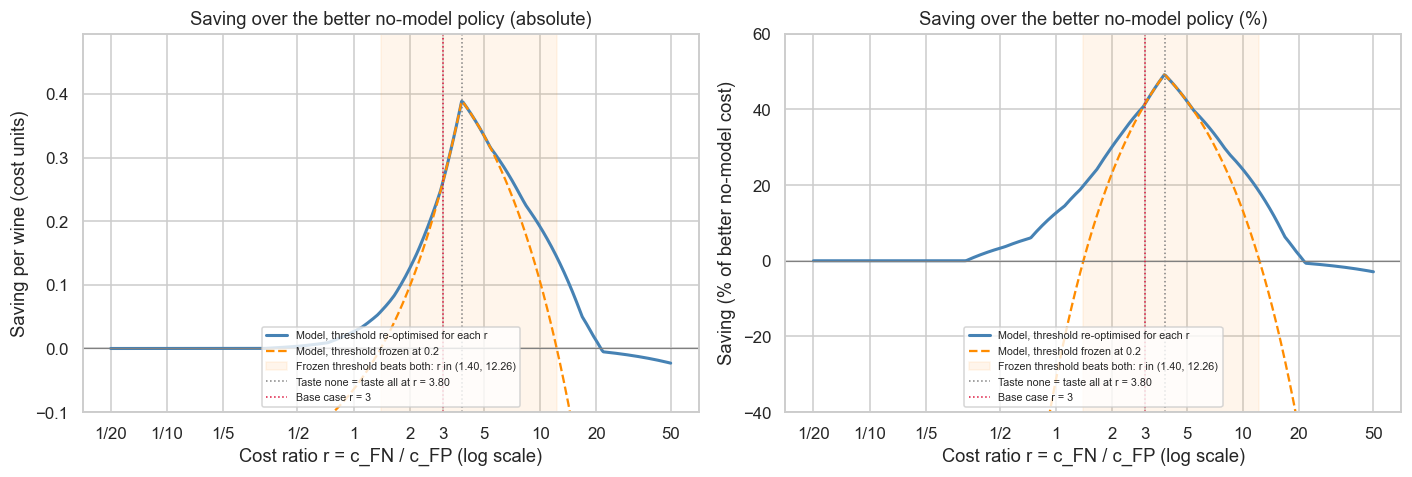

Break-even range of the frozen threshold: 1.40 < r < 12.26
Largest absolute saving (re-optimised): 0.388 per wine at r = 3.79
At r = 3: saving 0.260 per wine, 41.6% of the better no-model policy (taste none)


In [63]:
r_grid = np.logspace(np.log10(1/20), np.log10(50), 400)
best_nm = np.minimum(r_grid * pi, 1 - pi)
reopt = np.array([((FP_t + r * FN_t) / n).min() for r in r_grid])
frozen = (fp + r_grid * fn) / n

lo_be, hi_be = fp / tp, tn / fn
beats = (frozen < r_grid * pi) & (frozen < 1 - pi)
assert np.isclose(r_grid[beats].min(), lo_be, rtol=0.02) and np.isclose(r_grid[beats].max(), hi_be, rtol=0.02)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, scale, ylab in [(axes[0], 1, 'Saving per wine (cost units)'),
                        (axes[1], 100, 'Saving (% of better no-model cost)')]:
    denom = best_nm if scale == 100 else 1
    ax.plot(r_grid, scale * (best_nm - reopt) / denom, lw=2, color='steelblue',
            label='Model, threshold re-optimised for each r')
    ax.plot(r_grid, scale * (best_nm - frozen) / denom, lw=1.5, ls='--', color='darkorange',
            label=f'Model, threshold frozen at {t_op:g}')
    ax.axvspan(lo_be, hi_be, color='darkorange', alpha=0.08,
               label=f'Frozen threshold beats both: r in ({lo_be:.2f}, {hi_be:.2f})')
    ax.axhline(0, color='grey', lw=0.8)
    ax.axvline((1 - pi) / pi, color='grey', ls=':', lw=1,
               label=f'Taste none = taste all at r = {(1 - pi) / pi:.2f}')
    ax.axvline(C_FN_BASE, color='crimson', ls=':', lw=1, label=f'Base case r = {C_FN_BASE}')
    ax.set_xscale('log')
    ticks = [0.05, 0.1, 0.2, 0.5, 1, 2, 3, 5, 10, 20, 50]
    ax.set_xticks(ticks, [ratio_label(r) for r in ticks])
    ax.set(xlabel='Cost ratio r = c_FN / c_FP (log scale)', ylabel=ylab)
    ax.legend(fontsize=7, loc='lower center')
axes[0].set_ylim(bottom=-0.1)
axes[1].set_ylim(-40, 60)
axes[0].set_title('Saving over the better no-model policy (absolute)')
axes[1].set_title('Saving over the better no-model policy (%)')
plt.tight_layout()
plt.show()

i_peak = np.argmax(best_nm - reopt)
print(f'Break-even range of the frozen threshold: {lo_be:.2f} < r < {hi_be:.2f}')
print(f'Largest absolute saving (re-optimised): {(best_nm - reopt)[i_peak]:.3f} per wine at r = {r_grid[i_peak]:.2f}')
print(f'At r = {C_FN_BASE}: saving {base["saving (abs)"]:.3f} per wine, '
      f'{base["saving (%)"]:.1f}% of the better no-model policy ({base["better no-model"]})')

**Where the model is worth using.** With its threshold re-optimised for each ratio, the model never costs more than the better no-model policy, but the saving is only material in the middle range: under 4% for $r \le 1/2$, 13% at $r = 1$, 30-42% for $r$ from 2 to 5, and 24% at $r = 10$. The largest absolute saving, 0.388 per wine, is at $r \approx 3.79$, next to the point ($r = 3.80$) where *taste none* and *taste all* cost the same. The saving shrinks at both extremes because one no-model policy is then already almost optimal. When misses are cheap (small $r$), tasting nothing is nearly the best possible, and the model can only help by flagging the few wines it is very confident are good. When misses are expensive (large $r$), tasting nearly everything is nearly the best possible, and the model can only help by ruling out the few wines it is very confident are not good. In between, the model's ranking changes the decision for many wines.

**Break-even and the choice of $c_{FN} = 3$.** With the threshold frozen at 0.20 (TP = 514, FP = 718, TN = 1,790, FN = 146), the model beats both no-model policies for $FP/TP = 1.40 < r < TN/FN = 12.26$, and the base case $r = 3$ sits well inside this range. Our $r = 3$ comes from valuing a good batch's premium at about 4 tasting fees ($r$ = premium − 1 fee), so the same conclusion holds for any premium between about 2.4 and 13.3 tasting fees: the decision to screen with the model does not hinge on the exact figure of 4. Below $r \approx 1.40$ tasting nothing is cheaper, and above $r \approx 12.3$ tasting everything is cheaper, unless the threshold is re-tuned.

**Framing.** Suppose the model were used instead as a standalone judge, with its verdict alone deciding which wines are sold as premium and no panel involved. The model, its predicted probabilities, and its PR-AUC and ROC-AUC would be exactly the same; only the costs change. A false positive now sells an ordinary wine as premium, which risks the brand, so it should cost more than a missed premium sale ($r < 1$). The $r < 1$ rows of the sensitivity table show what the model is then worth: a saving of only 3.3% at $r = 1/2$ and 0.2% at $r = 1/3$ (0.003 and under 0.001 per wine), because when false alarms are expensive the best policy flags almost nothing. As a screen in front of the panel ($r = 3$) the saving is 42%. **The model adds little value as a standalone judge and most value as a screen in front of the panel**, which is why we keep the tasting-panel framing.

### Bootstrap interval for the optimal threshold at $r = 3$

Optimal threshold at r = 3: 0.2; 95% bootstrap interval 0.20-0.30 (theory t* = 0.25)


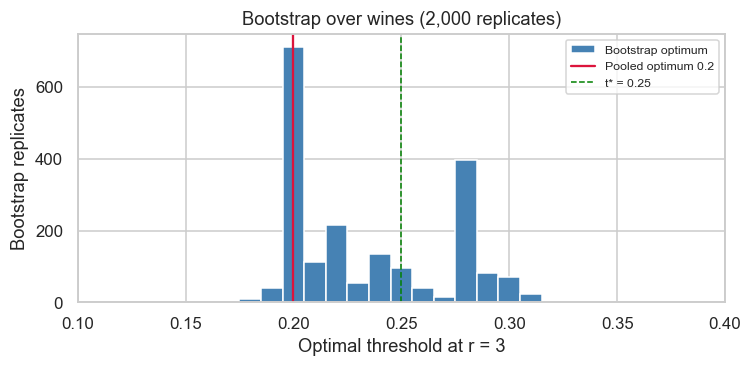

In [64]:
rng = np.random.default_rng(SEED)
cost_cols = np.where(y[:, None] == 1, C_FN_BASE * ~flag, C_FP * flag).astype(float)  # rows x grid
B = 2000
t_boot = np.empty(B)
for b in range(B):
    w = np.bincount(rng.integers(0, n, n), minlength=n)   # resample wines with replacement
    t_boot[b] = grid[(w @ cost_cols).argmin()]
lo_t, hi_t = np.percentile(t_boot, [2.5, 97.5])
print(f'Optimal threshold at r = {C_FN_BASE}: {t_op:g}; 95% bootstrap interval {lo_t:.2f}-{hi_t:.2f} '
      f'(theory t* = {1 / (1 + C_FN_BASE):.2f})')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(t_boot, bins=np.arange(grid.min() - 0.005, grid.max(), 0.01), color='steelblue', edgecolor='white',
        label='Bootstrap optimum')
ax.axvline(t_op, color='crimson', lw=1.5, label=f'Pooled optimum {t_op:g}')
ax.axvline(1 / (1 + C_FN_BASE), color='green', ls='--', lw=1, label=f't* = {1 / (1 + C_FN_BASE):.2f}')
ax.set(xlim=(max(0, lo_t - 0.1), hi_t + 0.1), xlabel='Optimal threshold at r = 3',
       ylabel='Bootstrap replicates', title='Bootstrap over wines (2,000 replicates)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Resampling wines gives a 95% interval of 0.20-0.30 for the optimal threshold at $r = 3$. It contains the theoretical $t^* = 0.25$. The pooled optimum (0.20) sits at the lower end of this interval, and the fold-by-fold optima average 0.24, so the true optimum is probably a little above 0.20. This matters little in practice: the cost curve stays within 5% of its minimum for every threshold from 0.18 to 0.31.

### Save the operating point

In [65]:
nm = no_model_costs(pi, C_FN_BASE)
operating_point = {
    'model': spec['name'], 'cost_ratio': C_FN_BASE, 'threshold': t_op,
    'theoretical_threshold': 1 / (1 + C_FN_BASE),
    'threshold_bootstrap_95ci': [float(lo_t), float(hi_t)],
    'cv_share_good': float(pi),
    'cv_sensitivity': tp / (tp + fn), 'cv_specificity': tn / (tn + fp),
    'cv_precision': precision,
    'cv_cost_per_wine': float(base['cost @ t optimal']),
    'cv_cost_taste_none': float(nm['taste none']), 'cv_cost_taste_all': float(nm['taste all']),
    'cv_saving_abs': float(base['saving (abs)']), 'cv_saving_pct': float(base['saving (%)']),
    'break_even_cost_ratio': [float(lo_be), float(hi_be)],
    'counts_at_threshold': {'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn},
    'break_even_formula': 'FP/TP < r < TN/FN',
}
with open('results/operating_point.json', 'w') as f:
    json.dump(operating_point, f, indent=2)
operating_point

{'model': 'Logistic',
 'cost_ratio': 3,
 'threshold': 0.2,
 'theoretical_threshold': 0.25,
 'threshold_bootstrap_95ci': [0.2, 0.3],
 'cv_share_good': 0.20833333333333334,
 'cv_sensitivity': 0.7787878787878788,
 'cv_specificity': 0.7137161084529505,
 'cv_precision': 0.4172077922077922,
 'cv_cost_per_wine': 0.3648989898989899,
 'cv_cost_taste_none': 0.625,
 'cv_cost_taste_all': 0.7916666666666666,
 'cv_saving_abs': 0.2601010101010101,
 'cv_saving_pct': 41.61616161616162,
 'break_even_cost_ratio': [1.3968871595330739, 12.26027397260274],
 'counts_at_threshold': {'TP': 514, 'FP': 718, 'TN': 1790, 'FN': 146},
 'break_even_formula': 'FP/TP < r < TN/FN'}

# Part 5: Test set and final refit

The model, its predictor subset and the threshold are frozen from Parts 3 and 4 (`results/selected_model.json`, `results/operating_point.json`). This part loads the test set for the first and only time (793 wines, one row per wine), scores the frozen model on it, reports the test results side by side with the CV estimates, and then refits the same specification on all 3,961 wines. Nothing is changed after the test results are seen.

Up to this point the test set has been locked by code (Part 0). It is unlocked here, for this part only.

In [66]:
assert not test_load_attempts, 'the test set was read before Part 5'
TEST_SET_UNLOCKED = True
print('Test set unlocked.')

Test set unlocked.


In [67]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)


sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

spec = json.load(open('results/selected_model.json'))
op = json.load(open('results/operating_point.json'))
assert op['model'] == spec['name']
t = op['threshold']
X_train, y_train = load_train()
print(f"Frozen: {spec['name']} on {spec['n_predictors']} predictors {spec['predictors']}, threshold {t:g}")

Frozen: Logistic on 6 predictors ['fixed acidity', 'log residual sugar', 'free sulfur dioxide', 'density', 'pH', 'log sulphates'], threshold 0.2


### Fit the frozen specification on the full training set

In [68]:
model = build_selected(spec).fit(X_train, y_train)
assert model.named_steps['model'].n_features_in_ == len(spec['predictors'])
assert list(model[:-1].get_feature_names_out()) == spec['predictors']
print(spec['name'], 'fitted on', len(X_train), 'training wines')
model

Logistic fitted on 3168 training wines


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','log volatile acidity','citric acid',...,'pH', 'log sulphates','alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('keep', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to sett

### Score the test set, once

Test wines: 793 | share good: 0.208 | no duplicates, no overlap with training


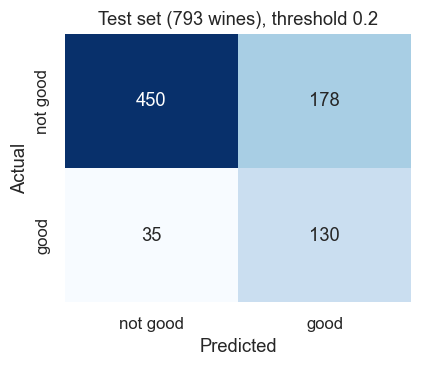

In [69]:
X_test, y_test = load_test()
train_df, test_df = load_split('train'), load_split('test')
assert len(X_test) == 793 and not test_df.duplicated().any()
assert len(train_df.merge(test_df, how='inner')) == 0, 'a wine appears in both train and test'
print('Test wines:', len(y_test), '| share good:', round(y_test.mean(), 3),
      '| no duplicates, no overlap with training')

prob = model.predict_proba(X_test)[:, 1]
tn, fp, fn, tp = confusion_matrix(y_test, prob >= t).ravel()
test = {'PR-AUC': average_precision_score(y_test, prob),
        'ROC-AUC': roc_auc_score(y_test, prob),
        f'Sensitivity @{t:g}': tp / (tp + fn),
        f'Specificity @{t:g}': tn / (tn + fp),
        f'Cost per wine @{t:g}': expected_cost(y_test, prob, t, C_FN_BASE)}

fig, ax = plt.subplots(figsize=(4, 3.5))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
            xticklabels=['not good', 'good'], yticklabels=['not good', 'good'])
ax.set(xlabel='Predicted', ylabel='Actual', title=f'Test set ({len(y_test)} wines), threshold {t:g}')
plt.tight_layout()
plt.show()

#### CV estimates and test results side by side

CV values are mean ± SE over the 10 folds of the nested CV in Part 3 (out-of-fold predictions of the selected model; sensitivity, specificity and cost at the chosen threshold are computed per fold from the same predictions).

In [70]:
oof = pd.read_csv('results/oof_probabilities.csv', index_col=0)
cv_folds = []
for f, d in oof.groupby('fold'):
    p, yy = d[spec['name']].to_numpy(), d['y'].to_numpy()
    c_tn, c_fp, c_fn, c_tp = confusion_matrix(yy, p >= t, labels=[0, 1]).ravel()
    cv_folds.append({'PR-AUC': average_precision_score(yy, p), 'ROC-AUC': roc_auc_score(yy, p),
                     f'Sensitivity @{t:g}': c_tp / (c_tp + c_fn), f'Specificity @{t:g}': c_tn / (c_tn + c_fp),
                     f'Cost per wine @{t:g}': expected_cost(yy, p, t, C_FN_BASE)})
cv_folds = pd.DataFrame(cv_folds)
assert np.isclose(cv_folds['PR-AUC'].mean(), spec['cv_pr_auc_mean'])

comparison = pd.DataFrame({
    'CV mean': cv_folds.mean(),
    'CV SE': cv_folds.std() / np.sqrt(len(cv_folds)),
    'Test': pd.Series(test),
})
comparison['|Test - CV|'] = (comparison['Test'] - comparison['CV mean']).abs()
comparison.to_csv('results/test_vs_cv.csv')
comparison.round(3)

,CV mean,CV SE,Test,|Test - CV|
PR-AUC,0.535,0.018,0.544,0.010
ROC-AUC,0.802,0.011,0.820,0.018
Sensitivity @0.2,0.779,0.017,0.788,0.009
Specificity @0.2,0.714,0.009,0.717,0.003
Cost per wine @0.2,0.365,0.011,0.357,0.008


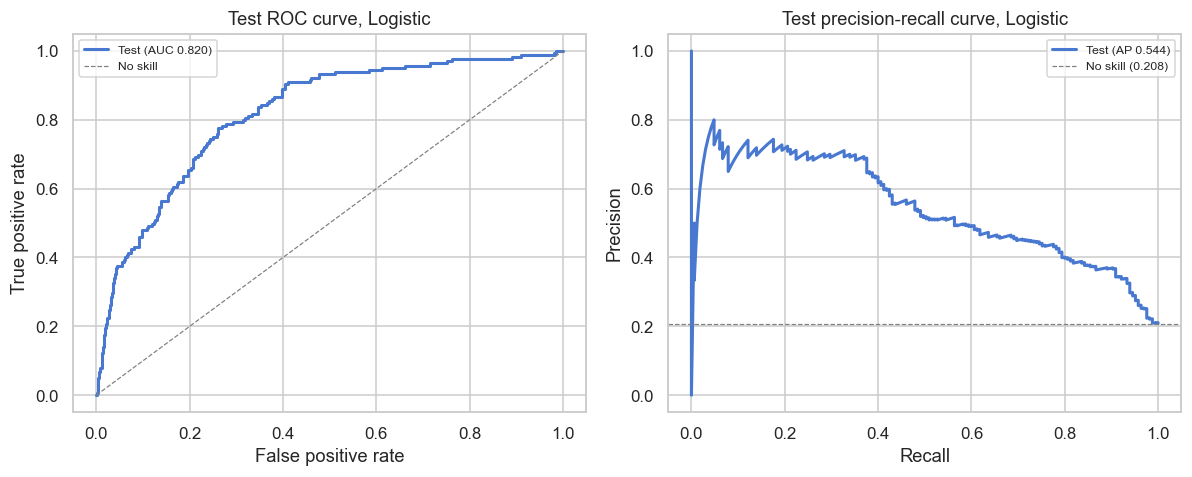

In [71]:
fpr, tpr, _ = roc_curve(y_test, prob)
prec, rec, _ = precision_recall_curve(y_test, prob)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, lw=2, label=f"Test (AUC {test['ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color='grey', ls='--', lw=0.8, label='No skill')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title=f'Test ROC curve, {spec["name"]}')
axes[1].plot(rec, prec, lw=2, label=f"Test (AP {test['PR-AUC']:.3f})")
axes[1].axhline(y_test.mean(), color='grey', ls='--', lw=0.8, label=f'No skill ({y_test.mean():.3f})')
axes[1].set(xlabel='Recall', ylabel='Precision', title=f'Test precision-recall curve, {spec["name"]}')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Refit the same specification on all data (3,961 wines)

Only the parameters are re-estimated. The selected predictor subset, transformations, model family and threshold stay frozen, and the performance figures to report remain the test results above. Predictors are standardised over the full data, so effects are per one-SD increase.

- **Logistic:** sklearn gives no standard errors, so the same unpenalised model is refitted in `statsmodels`. Each row is a different wine, so the usual model-based SEs are used. We report odds ratios per 1 SD.
- **LDA:** standardised discriminant coefficients (the weight of each predictor in the linear discriminant) and the standardised difference in class means.
- **Gaussian NB:** the standardised difference in class means for each predictor, which drives its per-feature likelihood ratio.

In [72]:
df_all = load_all()
assert len(df_all) == 3961
X_all = transform(df_all[ALL_FEATURES])
y_all = (df_all['quality'] >= 7).astype(int)

final_model = build_selected(spec).fit(X_all, y_all)   # the deployable model; selects spec['predictors']
Z_all = X_all[spec['predictors']]
Z_all = (Z_all - Z_all.mean()) / Z_all.std()

if spec['name'] == 'Logistic':
    final = sm.Logit(y_all, sm.add_constant(Z_all)).fit(disp=0)
    print(final.summary())
    ci = final.conf_int()
    effects = pd.DataFrame({
        'coef (log-odds per SD)': final.params,
        'odds ratio per SD': np.exp(final.params),
        'OR 95% CI low': np.exp(ci[0]),
        'OR 95% CI high': np.exp(ci[1]),
        'p-value': final.pvalues,
    }).drop('const').sort_values('odds ratio per SD', ascending=False)
else:
    mean_diff = Z_all[y_all == 1].mean() - Z_all[y_all == 0].mean()
    effects = pd.DataFrame({'class mean difference (good - not good, SDs)': mean_diff})
    if spec['name'] == 'LDA':
        lda = final_model.named_steps['model']
        effects['standardised discriminant coefficient'] = lda.scalings_[:, 0]
    effects = effects.sort_values(effects.columns[-1], key=np.abs, ascending=False)
effects.to_csv('results/refit_effects.csv')
effects.round(3)

                           Logit Regression Results                           
Dep. Variable:                quality   No. Observations:                 3961
Model:                          Logit   Df Residuals:                     3954
Method:                           MLE   Df Model:                            6
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.2047
Time:                        09:44:00   Log-Likelihood:                -1611.9
converged:                       True   LL-Null:                       -2026.7
Covariance Type:            nonrobust   LLR p-value:                5.900e-176
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -1.7757      0.054    -32.756      0.000      -1.882      -1.669
fixed acidity           0.5460      0.059      9.215      0.000       0.430       0.662
log residual sug

,coef (log-odds per SD),odds ratio per SD,OR 95% CI low,OR 95% CI high,p-value
log residual sugar,1.138,3.120,2.690,3.619,0.0
pH,0.640,1.897,1.702,2.113,0.0
fixed acidity,0.546,1.726,1.537,1.939,0.0
free sulfur dioxide,0.217,1.243,1.130,1.366,0.0
log sulphates,0.210,1.234,1.134,1.343,0.0
density,-2.123,0.120,0.100,0.143,0.0


### Limitations

- **Binarised outcome.** Quality is cut at 7, so the ordering within each class (a 3 vs a 6, a 7 vs a 9) is lost, and wines just either side of the cut are treated as fully different.
- **Noisy labels.** Each quality score is the median of at least three expert ratings, so some labels near the cut-off are effectively uncertain, which caps achievable accuracy.
- **One region and vintage period.** The data are Vinho Verde wines from a 2009 study (Cortez et al.). Results may not transfer to other regions, styles or later vintages.
- **Missing drivers.** There is no price, grape variety, brand or cost information, so the cost ratio $c_{FN}/c_{FP}$ is assumed, not measured (see the sensitivity analysis in Part 4).
- **White wine only.** No conclusion is drawn about red wine.
- **Simplicity has a price.** Each classifier uses the simplest predictor subset within one SE of its best (Part 3), which gives up a little PR-AUC; the paired difference against all 11 predictors is reported in Part 3. Correlated predictors (density, residual sugar, alcohol) can stand in for each other, so the odds ratios above should be read together rather than one at a time.
- **CV variance.** CV estimates come from one 10-fold split of 3,168 wines. The fold-to-fold SE (about 0.017 in PR-AUC) is larger than the gaps between the three classifiers, so the choice between them is not clear-cut, and the test set is one further draw of 793 wines.